In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Hourly total-sales dataset.csv")

df.head()

,Hours_Start,Sale_Day,Sale_Hour,Transaction_Count,Total_Quantity,Hourly_Sales
0,2024-12-19 16:00:00.000,2024-12-19,16,3,3.0,0.03
1,2024-12-25 12:00:00.000,2024-12-25,12,1,4.0,6.36
2,2024-12-25 13:00:00.000,2024-12-25,13,6,8.0,15.60
3,2024-12-25 14:00:00.000,2024-12-25,14,2,4.0,35.10
4,2024-12-25 15:00:00.000,2024-12-25,15,4,6.0,15.56


In [97]:
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

df = df.sort_values('Hours_Start').reset_index(drop=True)

print(df.shape)
print(df['Hours_Start'].min())
print(df['Hours_Start'].max())

(8616, 6)
2024-12-19 16:00:00
2026-07-15 16:00:00


In [98]:
df['hour'] = df['Hours_Start'].dt.hour
df['day_of_week'] = df['Hours_Start'].dt.dayofweek
df['day_of_month'] = df['Hours_Start'].dt.day
df['month'] = df['Hours_Start'].dt.month
df['year'] = df['Hours_Start'].dt.year
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

In [99]:
df['lag_1'] = df['Hourly_Sales'].shift(1)
df['lag_24'] = df['Hourly_Sales'].shift(24)
df['lag_168'] = df['Hourly_Sales'].shift(168)

df['rolling_mean_24'] = (
    df['Hourly_Sales']
    .shift(1)
    .rolling(24)
    .mean()
)

df['rolling_mean_168'] = (
    df['Hourly_Sales']
    .shift(1)
    .rolling(168)
    .mean()
)

In [100]:
df['days_to_month_end'] = (
    df['Hours_Start'].dt.days_in_month -
    df['Hours_Start'].dt.day
)

df['is_month_end'] = (
    df['days_to_month_end'] <= 2
).astype(int)

In [101]:
# Make sure datetime is correct
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Sort chronologically
df = df.sort_values('Hours_Start').reset_index(drop=True)

print("First:", df['Hours_Start'].min())
print("Last:", df['Hours_Start'].max())
print("Rows:", len(df))

# Difference between consecutive records
df['time_gap'] = df['Hours_Start'].diff()

print(df['time_gap'].value_counts().head(15))

First: 2024-12-19 16:00:00
Last: 2026-07-15 16:00:00
Rows: 8616
0 days 01:00:00    8005
0 days 10:00:00     274
0 days 09:00:00     224
0 days 11:00:00      58
0 days 02:00:00      41
0 days 12:00:00       6
0 days 13:00:00       2
0 days 08:00:00       2
5 days 20:00:00       1
0 days 14:00:00       1
0 days 03:00:00       1
Name: time_gap, dtype: int64


In [102]:
print("Gaps greater than 1 hour:",
      (df['time_gap'] > pd.Timedelta(hours=1)).sum())

Gaps greater than 1 hour: 610


In [103]:
df['lag_1'] = df['Hourly_Sales'].shift(1)
df['lag_24'] = df['Hourly_Sales'].shift(24)
df['lag_168'] = df['Hourly_Sales'].shift(168)

In [104]:
df['days_to_month_end'] = (
    df['Hours_Start'].dt.days_in_month -
    df['Hours_Start'].dt.day
)

df['is_month_end'] = (
    df['days_to_month_end'] <= 2
).astype(int)

In [105]:
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()

print("Training:", train.shape)
print("Testing:", test.shape)

print("\nTraining period:")
print(train['Hours_Start'].min(), "to", train['Hours_Start'].max())

print("\nTesting period:")
print(test['Hours_Start'].min(), "to", test['Hours_Start'].max())

Training: (6892, 20)
Testing: (1724, 20)

Training period:
2024-12-19 16:00:00 to 2026-03-26 07:00:00

Testing period:
2026-03-26 08:00:00 to 2026-07-15 16:00:00


In [106]:
# Make sure data is sorted by time
df = df.sort_values('Hours_Start').reset_index(drop=True)

# Calculate time difference between consecutive rows
df['time_gap'] = df['Hours_Start'].diff()

print("Time gap frequencies:")
print(df['time_gap'].value_counts().sort_index())

print("\nNumber of gaps greater than 1 hour:")
print((df['time_gap'] > pd.Timedelta(hours=1)).sum())

Time gap frequencies:
0 days 01:00:00    8005
0 days 02:00:00      41
0 days 03:00:00       1
0 days 08:00:00       2
0 days 09:00:00     224
0 days 10:00:00     274
0 days 11:00:00      58
0 days 12:00:00       6
0 days 13:00:00       2
0 days 14:00:00       1
5 days 20:00:00       1
Name: time_gap, dtype: int64

Number of gaps greater than 1 hour:
610


In [107]:
# train_test_split(df, test_size=0.2, random_state=42)

In [108]:
# Show some of the missing/gap periods
gaps = df[df['time_gap'] > pd.Timedelta(hours=1)]

gaps[['Hours_Start', 'time_gap']].head(20)

,Hours_Start,time_gap
1,2024-12-25 12:00:00,5 days 20:00:00
11,2024-12-26 11:00:00,0 days 14:00:00
20,2024-12-27 08:00:00,0 days 13:00:00
23,2024-12-27 12:00:00,0 days 02:00:00
30,2024-12-27 20:00:00,0 days 02:00:00
33,2024-12-28 09:00:00,0 days 11:00:00
47,2024-12-29 08:00:00,0 days 10:00:00
51,2024-12-29 13:00:00,0 days 02:00:00
58,2024-12-30 08:00:00,0 days 13:00:00
60,2024-12-30 11:00:00,0 days 02:00:00


In [109]:
df = df.drop(
    columns=[
        'lag_1',
        'lag_24',
        'lag_168',
        'rolling_mean_24',
        'rolling_mean_168'
    ],
    errors='ignore'
)

In [110]:
# Make timestamp unique and chronological
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])
df = df.sort_values('Hours_Start').reset_index(drop=True)

# Create lookup series
sales_lookup = df.set_index('Hours_Start')['Hourly_Sales']

df['lag_1h'] = (
    df['Hours_Start'] - pd.Timedelta(hours=1)
).map(sales_lookup)

df['lag_24h'] = (
    df['Hours_Start'] - pd.Timedelta(hours=24)
).map(sales_lookup)

df['lag_7d'] = (
    df['Hours_Start'] - pd.Timedelta(days=7)
).map(sales_lookup)

In [111]:
df[
    ['Hours_Start', 'Hourly_Sales',
     'lag_1h', 'lag_24h', 'lag_7d']
].head(30)

,Hours_Start,Hourly_Sales,lag_1h,lag_24h,lag_7d
0,2024-12-19 16:00:00,0.03,NaN,NaN,NaN
1,2024-12-25 12:00:00,6.36,NaN,NaN,NaN
2,2024-12-25 13:00:00,15.60,6.36,NaN,NaN
3,2024-12-25 14:00:00,35.10,15.60,NaN,NaN
4,2024-12-25 15:00:00,15.56,35.10,NaN,NaN
5,2024-12-25 16:00:00,2.58,15.56,NaN,NaN
6,2024-12-25 17:00:00,22.40,2.58,NaN,NaN
7,2024-12-25 18:00:00,3.05,22.40,NaN,NaN
8,2024-12-25 19:00:00,34.93,3.05,NaN,NaN
9,2024-12-25 20:00:00,46.31,34.93,NaN,NaN


In [112]:
print("Missing lag_1h:")
print(df['lag_1h'].isna().sum())

print("\nMissing lag_24h:")
print(df['lag_24h'].isna().sum())

print("\nMissing lag_7d:")
print(df['lag_7d'].isna().sum())

Missing lag_1h:
611

Missing lag_24h:
303

Missing lag_7d:
285


In [113]:
df.dropna()


,Hours_Start,Sale_Day,Sale_Hour,Transaction_Count,Total_Quantity,Hourly_Sales,hour,day_of_week,day_of_month,month,year,is_weekend,days_to_month_end,is_month_end,time_gap,lag_1h,lag_24h,lag_7d
16,2024-12-26 16:00:00,2024-12-26,16,5,8.0,16.19,16,3,26,12,2024,0,5,0,0 days 01:00:00,23.20,2.58,0.03
90,2025-01-01 12:00:00,2025-01-01,12,1,1.0,1.99,12,2,1,1,2025,0,30,0,0 days 01:00:00,14.25,4.79,6.36
91,2025-01-01 13:00:00,2025-01-01,13,2,6.0,7.92,13,2,1,1,2025,0,30,0,0 days 01:00:00,1.99,22.51,15.60
92,2025-01-01 14:00:00,2025-01-01,14,1,1.0,1.69,14,2,1,1,2025,0,30,0,0 days 01:00:00,7.92,22.66,35.10
93,2025-01-01 15:00:00,2025-01-01,15,3,22.0,32.81,15,2,1,1,2025,0,30,0,0 days 01:00:00,1.69,4.43,15.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8611,2026-07-15 12:00:00,2026-07-15,12,16,33.0,64.18,12,2,15,7,2026,0,16,0,0 days 01:00:00,203.36,204.60,100.30
8612,2026-07-15 13:00:00,2026-07-15,13,20,67.0,217.43,13,2,15,7,2026,0,16,0,0 days 01:00:00,64.18,105.88,105.60
8613,2026-07-15 14:00:00,2026-07-15,14,16,37.0,81.19,14,2,15,7,2026,0,16,0,0 days 01:00:00,217.43,64.52,159.56
8614,2026-07-15 15:00:00,2026-07-15,15,20,40.0,119.57,15,2,15,7,2026,0,16,0,0 days 01:00:00,81.19,163.78,52.07


In [114]:
baseline_df = df.dropna(subset=['lag_7d']).copy()

print("Original rows:", len(df))
print("Baseline rows:", len(baseline_df))
print("Rows removed:", len(df) - len(baseline_df))

Original rows: 8616
Baseline rows: 8331
Rows removed: 285


In [115]:
split_index = int(len(baseline_df) * 0.8)

train = baseline_df.iloc[:split_index].copy()
test = baseline_df.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train['Hours_Start'].min(), "to", train['Hours_Start'].max())

print("\nTesting period:")
print(test['Hours_Start'].min(), "to", test['Hours_Start'].max())

Training rows: 6664
Testing rows: 1667

Training period:
2024-12-26 16:00:00 to 2026-03-28 12:00:00

Testing period:
2026-03-28 13:00:00 to 2026-07-15 16:00:00


In [116]:
y_test = test['Hourly_Sales']
baseline_pred = test['lag_7d']

In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_pred
    )
)

print("Naive 7-Day Baseline")
print("--------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))

Naive 7-Day Baseline
--------------------
MAE: 39.56
RMSE: 61.56


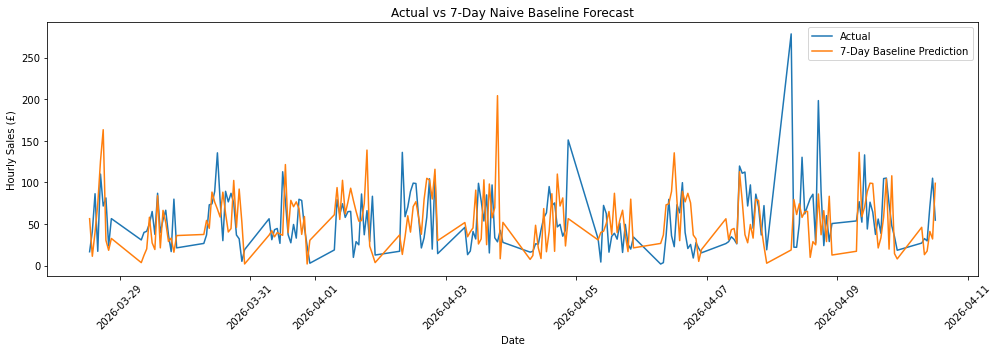

In [118]:
plt.figure(figsize=(14, 5))

sample = test.head(200)

plt.plot(
    sample['Hours_Start'],
    sample['Hourly_Sales'],
    label='Actual'
)

plt.plot(
    sample['Hours_Start'],
    sample['lag_7d'],
    label='7-Day Baseline Prediction'
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs 7-Day Naive Baseline Forecast')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [119]:
from prophet import Prophet

In [120]:
# !pip install prophet

In [121]:
prophet_data = df[['Hours_Start', 'Hourly_Sales']].copy()

prophet_data = prophet_data.rename(columns={
    'Hours_Start': 'ds',
    'Hourly_Sales': 'y'
})

prophet_data = prophet_data.sort_values('ds').reset_index(drop=True)

prophet_data.head()

,ds,y
0,2024-12-19 16:00:00,0.03
1,2024-12-25 12:00:00,6.36
2,2024-12-25 13:00:00,15.60
3,2024-12-25 14:00:00,35.10
4,2024-12-25 15:00:00,15.56


In [122]:
split_index = int(len(prophet_data) * 0.8)

prophet_train = prophet_data.iloc[:split_index].copy()
prophet_test = prophet_data.iloc[split_index:].copy()

print("Training:", prophet_train.shape)
print("Testing:", prophet_test.shape)

print("\nTraining period:")
print(prophet_train['ds'].min(), "to", prophet_train['ds'].max())

print("\nTesting period:")
print(prophet_test['ds'].min(), "to", prophet_test['ds'].max())

Training: (6892, 2)
Testing: (1724, 2)

Training period:
2024-12-19 16:00:00 to 2026-03-26 07:00:00

Testing period:
2026-03-26 08:00:00 to 2026-07-15 16:00:00


In [123]:
model_prophet = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True
)

model_prophet.fit(prophet_train)

08:58:20 - cmdstanpy - INFO - Chain [1] start processing
08:58:22 - cmdstanpy - INFO - Chain [1] done processing


In [124]:
future = prophet_test[['ds']].copy()

prophet_forecast = model_prophet.predict(future)

In [125]:
prophet_forecast[
    ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
].head()

,ds,yhat,yhat_lower,yhat_upper
0,2026-03-26 08:00:00,35.495092,-5.403288,75.657683
1,2026-03-26 09:00:00,36.863350,-2.269844,76.664295
2,2026-03-26 10:00:00,42.715516,3.405964,83.335581
3,2026-03-26 11:00:00,50.109618,12.067527,90.754042
4,2026-03-26 12:00:00,53.627118,11.310178,94.085117


In [126]:
prophet_actual = prophet_test['y'].values
prophet_pred = prophet_forecast['yhat'].values

prophet_mae = mean_absolute_error(
    prophet_actual,
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_actual,
        prophet_pred
    )
)

print("Prophet - Without Payday Features")
print("---------------------------------")
print("MAE:", round(prophet_mae, 2))
print("RMSE:", round(prophet_rmse, 2))

Prophet - Without Payday Features
---------------------------------
MAE: 44.13
RMSE: 65.24


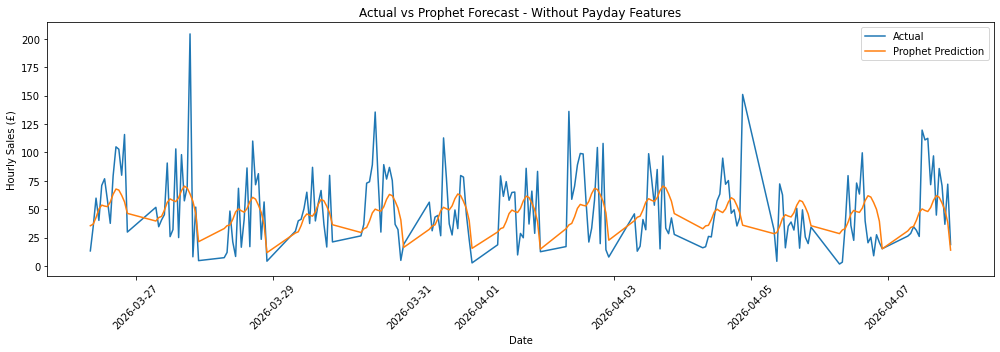

In [127]:
plt.figure(figsize=(14, 5))

n = 200

plt.plot(
    prophet_test['ds'].iloc[:n],
    prophet_test['y'].iloc[:n],
    label='Actual'
)

plt.plot(
    prophet_test['ds'].iloc[:n],
    prophet_forecast['yhat'].iloc[:n],
    label='Prophet Prediction'
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs Prophet Forecast - Without Payday Features')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [128]:
# here i try after pay day

In [129]:
# Start from the Prophet dataset
prophet_payday = prophet_data.copy()

# Days remaining until the end of each month
prophet_payday['days_to_month_end'] = (
    prophet_payday['ds'].dt.days_in_month -
    prophet_payday['ds'].dt.day
)

# Payday window:
# last 2 days of the month + first 2 days of next month
prophet_payday['is_payday_period'] = (
    (prophet_payday['days_to_month_end'] <= 1) |
    (prophet_payday['ds'].dt.day <= 2)
).astype(int)

prophet_payday[
    ['ds', 'y', 'days_to_month_end', 'is_payday_period']
].head(30)

,ds,y,days_to_month_end,is_payday_period
0,2024-12-19 16:00:00,0.03,12,0
1,2024-12-25 12:00:00,6.36,6,0
2,2024-12-25 13:00:00,15.60,6,0
3,2024-12-25 14:00:00,35.10,6,0
4,2024-12-25 15:00:00,15.56,6,0
5,2024-12-25 16:00:00,2.58,6,0
6,2024-12-25 17:00:00,22.40,6,0
7,2024-12-25 18:00:00,3.05,6,0
8,2024-12-25 19:00:00,34.93,6,0
9,2024-12-25 20:00:00,46.31,6,0


In [130]:
print(
    prophet_payday['is_payday_period'].value_counts()
)

prophet_payday[
    prophet_payday['is_payday_period'] == 1
][['ds', 'y', 'is_payday_period']].head(30)

0    7460
1    1156
Name: is_payday_period, dtype: int64


,ds,y,is_payday_period
58,2024-12-30 08:00:00,6.00,1
59,2024-12-30 09:00:00,24.37,1
60,2024-12-30 11:00:00,8.19,1
61,2024-12-30 12:00:00,26.06,1
62,2024-12-30 13:00:00,3.19,1
63,2024-12-30 14:00:00,22.77,1
64,2024-12-30 15:00:00,75.51,1
65,2024-12-30 16:00:00,30.26,1
66,2024-12-30 18:00:00,27.80,1
67,2024-12-30 19:00:00,11.82,1


In [131]:
split_index = int(len(prophet_payday) * 0.8)

payday_train = prophet_payday.iloc[:split_index].copy()
payday_test = prophet_payday.iloc[split_index:].copy()

print("Training:", payday_train.shape)
print("Testing:", payday_test.shape)

print(
    payday_train['ds'].min(),
    "to",
    payday_train['ds'].max()
)

print(
    payday_test['ds'].min(),
    "to",
    payday_test['ds'].max()
)

Training: (6892, 4)
Testing: (1724, 4)
2024-12-19 16:00:00 to 2026-03-26 07:00:00
2026-03-26 08:00:00 to 2026-07-15 16:00:00


In [132]:
model_prophet_payday = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True
)

model_prophet_payday.add_regressor(
    'is_payday_period'
)

model_prophet_payday.fit(
    payday_train[
        ['ds', 'y', 'is_payday_period']
    ]
)

08:58:25 - cmdstanpy - INFO - Chain [1] start processing
08:58:29 - cmdstanpy - INFO - Chain [1] done processing


In [133]:
future_payday = payday_test[
    ['ds', 'is_payday_period']
].copy()

forecast_payday = model_prophet_payday.predict(
    future_payday
)

In [134]:
payday_actual = payday_test['y'].values
payday_pred = forecast_payday['yhat'].values

payday_mae = mean_absolute_error(
    payday_actual,
    payday_pred
)

payday_rmse = np.sqrt(
    mean_squared_error(
        payday_actual,
        payday_pred
    )
)

print("Prophet - WITH Payday Feature")
print("--------------------------------")
print("MAE:", round(payday_mae, 2))
print("RMSE:", round(payday_rmse, 2))

Prophet - WITH Payday Feature
--------------------------------
MAE: 35.52
RMSE: 53.56


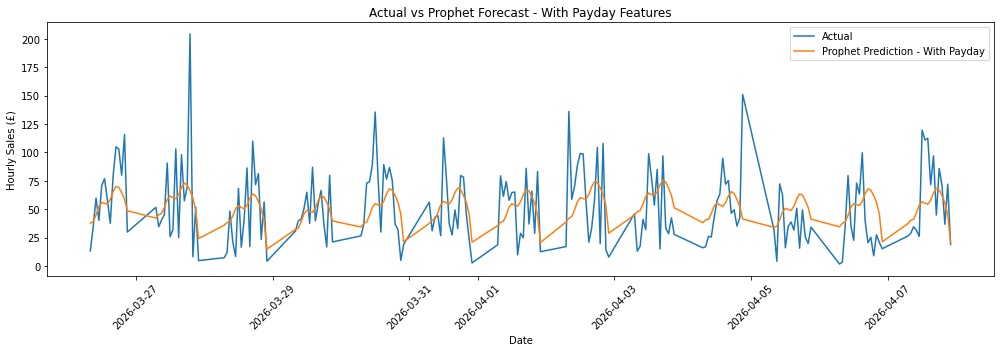

In [135]:
import matplotlib.pyplot as plt

# Number of observations to display
n = 200

plt.figure(figsize=(14, 5))

# Actual sales
plt.plot(
    payday_test['ds'].iloc[:n],
    payday_test['y'].iloc[:n],
    label='Actual'
)

# Prophet prediction WITH payday
plt.plot(
    payday_test['ds'].iloc[:n],
    forecast_payday['yhat'].iloc[:n],
    label='Prophet Prediction - With Payday'
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs Prophet Forecast - With Payday Features')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

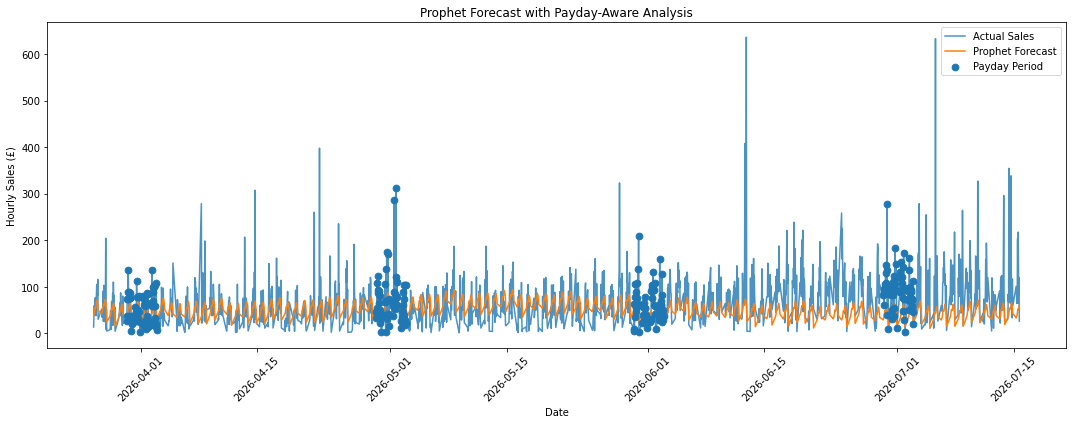

In [136]:
import matplotlib.pyplot as plt

# Use the full test period
plot_df = payday_test.copy()
plot_forecast = forecast_payday.copy()

plt.figure(figsize=(15, 6))

# Actual sales
plt.plot(
    plot_df['ds'],
    plot_df['y'],
    label='Actual Sales',
    alpha=0.8
)

# Prophet prediction
plt.plot(
    plot_forecast['ds'],
    plot_forecast['yhat'],
    label='Prophet Forecast'
)

# Highlight observations classified as payday period
payday_rows = plot_df[plot_df['is_payday_period'] == 1]

plt.scatter(
    payday_rows['ds'],
    payday_rows['y'],
    s=45,
    label='Payday Period',
    zorder=5
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Prophet Forecast with Payday-Aware Analysis')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [137]:
payday_analysis = (
    payday_test
    .groupby('is_payday_period')['y']
    .agg(['count', 'mean', 'median', 'std'])
)

payday_analysis.index = ['Non-Payday', 'Payday Period']

print(payday_analysis)

               count       mean  median        std
Non-Payday      1473  70.660978   61.11  52.417545
Payday Period    251  70.684263   64.78  46.265899


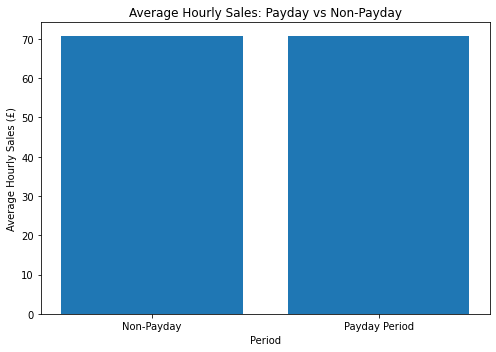

In [138]:
payday_avg = (
    payday_test
    .groupby('is_payday_period')['y']
    .mean()
)

plt.figure(figsize=(7,5))

plt.bar(
    ['Non-Payday', 'Payday Period'],
    payday_avg.values
)

plt.ylabel('Average Hourly Sales (£)')
plt.xlabel('Period')
plt.title('Average Hourly Sales: Payday vs Non-Payday')

plt.tight_layout()
plt.show()

In [139]:
print(df.columns.tolist())

['Hours_Start', 'Sale_Day', 'Sale_Hour', 'Transaction_Count', 'Total_Quantity', 'Hourly_Sales', 'hour', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'days_to_month_end', 'is_month_end', 'time_gap', 'lag_1h', 'lag_24h', 'lag_7d']


In [141]:
# print(df[['Hours_Start', 'days_to_month_end', 'is_payday_period']].head(20))

# print("\nUnique days_to_month_end values:")
# print(sorted(df['days_to_month_end'].dropna().unique())[:40])

# print("\nDate range:")
# print(df['Hours_Start'].min())
# print(df['Hours_Start'].max())

In [142]:
print(
    df[['Hours_Start', 'days_to_month_end']]
    .head(20)
)

print("\nUnique days_to_month_end:")
print(sorted(df['days_to_month_end'].dropna().unique()))

print("\nDate range:")
print("Start:", df['Hours_Start'].min())
print("End:", df['Hours_Start'].max())

           Hours_Start  days_to_month_end
0  2024-12-19 16:00:00                 12
1  2024-12-25 12:00:00                  6
2  2024-12-25 13:00:00                  6
3  2024-12-25 14:00:00                  6
4  2024-12-25 15:00:00                  6
5  2024-12-25 16:00:00                  6
6  2024-12-25 17:00:00                  6
7  2024-12-25 18:00:00                  6
8  2024-12-25 19:00:00                  6
9  2024-12-25 20:00:00                  6
10 2024-12-25 21:00:00                  6
11 2024-12-26 11:00:00                  5
12 2024-12-26 12:00:00                  5
13 2024-12-26 13:00:00                  5
14 2024-12-26 14:00:00                  5
15 2024-12-26 15:00:00                  5
16 2024-12-26 16:00:00                  5
17 2024-12-26 17:00:00                  5
18 2024-12-26 18:00:00                  5
19 2024-12-26 19:00:00                  5

Unique days_to_month_end:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 

In [143]:
df['is_payday_period'] = (
    df['days_to_month_end'] <= 2
).astype(int)

print(df[
    ['Hours_Start',
     'days_to_month_end',
     'is_payday_period']
].head(20))

           Hours_Start  days_to_month_end  is_payday_period
0  2024-12-19 16:00:00                 12                 0
1  2024-12-25 12:00:00                  6                 0
2  2024-12-25 13:00:00                  6                 0
3  2024-12-25 14:00:00                  6                 0
4  2024-12-25 15:00:00                  6                 0
5  2024-12-25 16:00:00                  6                 0
6  2024-12-25 17:00:00                  6                 0
7  2024-12-25 18:00:00                  6                 0
8  2024-12-25 19:00:00                  6                 0
9  2024-12-25 20:00:00                  6                 0
10 2024-12-25 21:00:00                  6                 0
11 2024-12-26 11:00:00                  5                 0
12 2024-12-26 12:00:00                  5                 0
13 2024-12-26 13:00:00                  5                 0
14 2024-12-26 14:00:00                  5                 0
15 2024-12-26 15:00:00                  

In [144]:
print(df['is_payday_period'].value_counts())

0    7748
1     868
Name: is_payday_period, dtype: int64


In [145]:
sorted(df['days_to_month_end'].dropna().unique())

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30]

In [146]:
# Make sure Hours_Start is datetime
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Calendar day of month
df['day_of_month'] = df['Hours_Start'].dt.day

# Number of days in each month
df['days_in_month'] = df['Hours_Start'].dt.days_in_month

# Distance from month-end
# Negative = before month-end
# 0 = month-end
df['payday_distance'] = (
    df['day_of_month'] - df['days_in_month']
)

# First 3 days of the next month become +1, +2, +3
df.loc[df['day_of_month'] <= 3, 'payday_distance'] = \
    df.loc[df['day_of_month'] <= 3, 'day_of_month']

# Keep only -3 to +3 for payday-window analysis
payday_window = df[
    df['payday_distance'].between(-3, 3)
].copy()

print(
    payday_window[
        ['Hours_Start', 'Hourly_Sales', 'payday_distance']
    ].head(30)
)

print("\nCounts:")
print(
    payday_window['payday_distance']
    .value_counts()
    .sort_index()
)

           Hours_Start  Hourly_Sales  payday_distance
33 2024-12-28 09:00:00         11.86               -3
34 2024-12-28 10:00:00          7.57               -3
35 2024-12-28 11:00:00         11.18               -3
36 2024-12-28 12:00:00         61.17               -3
37 2024-12-28 13:00:00         10.85               -3
38 2024-12-28 14:00:00         27.55               -3
39 2024-12-28 15:00:00          4.57               -3
40 2024-12-28 16:00:00         46.64               -3
41 2024-12-28 17:00:00          8.37               -3
42 2024-12-28 18:00:00         59.07               -3
43 2024-12-28 19:00:00          6.54               -3
44 2024-12-28 20:00:00         20.04               -3
45 2024-12-28 21:00:00         26.51               -3
46 2024-12-28 22:00:00          1.89               -3
47 2024-12-29 08:00:00          9.57               -2
48 2024-12-29 09:00:00          9.32               -2
49 2024-12-29 10:00:00          2.69               -2
50 2024-12-29 11:00:00      

In [147]:
payday_effect = (
    payday_window
    .groupby('payday_distance')['Hourly_Sales']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

print(payday_effect)

                 count   mean  median    std
payday_distance                             
-3                 293  56.73   50.38  40.04
-2                 288  54.55   51.08  35.77
-1                 290  56.51   45.82  47.84
 0                 290  52.95   45.44  36.19
 1                 287  55.43   47.62  42.65
 2                 289  50.31   44.05  35.24
 3                 292  51.52   44.91  38.34


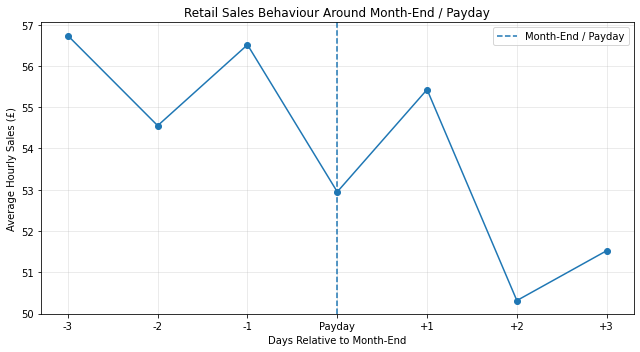

In [148]:
import matplotlib.pyplot as plt

payday_means = (
    payday_window
    .groupby('payday_distance')['Hourly_Sales']
    .mean()
)

plt.figure(figsize=(9, 5))

plt.plot(
    payday_means.index,
    payday_means.values,
    marker='o'
)

plt.axvline(
    x=0,
    linestyle='--',
    label='Month-End / Payday'
)

plt.xlabel('Days Relative to Month-End')
plt.ylabel('Average Hourly Sales (£)')
plt.title('Retail Sales Behaviour Around Month-End / Payday')
plt.xticks(
    [-3, -2, -1, 0, 1, 2, 3],
    ['-3', '-2', '-1', 'Payday', '+1', '+2', '+3']
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [149]:
from scipy.stats import mannwhitneyu

# Define payday window:
# 3 days before month-end through 3 days after
df['payday_window'] = (
    df['payday_distance'].between(-3, 3)
).astype(int)

payday_sales = df.loc[
    df['payday_window'] == 1,
    'Hourly_Sales'
].dropna()

non_payday_sales = df.loc[
    df['payday_window'] == 0,
    'Hourly_Sales'
].dropna()

print("Payday-window observations:", len(payday_sales))
print("Non-payday observations:", len(non_payday_sales))

print("\nAverage sales")
print("Payday window: £", round(payday_sales.mean(), 2))
print("Non-payday:    £", round(non_payday_sales.mean(), 2))

print("\nMedian sales")
print("Payday window: £", round(payday_sales.median(), 2))
print("Non-payday:    £", round(non_payday_sales.median(), 2))

# Mann-Whitney U test
stat, p_value = mannwhitneyu(
    payday_sales,
    non_payday_sales,
    alternative='two-sided'
)

print("\nMann-Whitney U Test")
print("-------------------")
print("Statistic:", round(stat, 2))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")

Payday-window observations: 2029
Non-payday observations: 6587

Average sales
Payday window: £ 54.0
Non-payday:    £ 52.78

Median sales
Payday window: £ 47.16
Non-payday:    £ 44.52

Mann-Whitney U Test
-------------------
Statistic: 6855063.0
P-value: 0.0782
Result: No statistically significant difference


In [150]:
# %pip install xgboost

In [151]:
# If XGBoost is not installed:
# !pip install xgboost

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Make sure data are ordered by time
df = df.sort_values('Hours_Start').copy()

# Features available in BOTH models
base_features = [
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'lag_1h',
    'lag_24h',
    'lag_7d'
]

# Remove rows where required lag features are missing
model_df = df.dropna(
    subset=base_features + ['Hourly_Sales', 'payday_window']
).copy()

# Chronological 80/20 split
split_index = int(len(model_df) * 0.8)

train = model_df.iloc[:split_index].copy()
test = model_df.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train['Hours_Start'].min(), "to", train['Hours_Start'].max())

print("\nTesting period:")
print(test['Hours_Start'].min(), "to", test['Hours_Start'].max())

Training observations: 6123
Testing observations: 1531

Training period:
2024-12-26 16:00:00 to 2026-03-29 13:00:00

Testing period:
2026-03-29 14:00:00 to 2026-07-15 16:00:00


In [152]:
X_train = train[base_features]
X_test = test[base_features]

y_train = train['Hourly_Sales']
y_test = test['Hourly_Sales']

xgb_without_payday = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_without_payday.fit(X_train, y_train)

pred_without = xgb_without_payday.predict(X_test)

mae_without = mean_absolute_error(y_test, pred_without)
rmse_without = np.sqrt(
    mean_squared_error(y_test, pred_without)
)

print("XGBoost WITHOUT Payday")
print("----------------------")
print("MAE:", round(mae_without, 2))
print("RMSE:", round(rmse_without, 2))

XGBoost WITHOUT Payday
----------------------
MAE: 36.36
RMSE: 55.29


In [153]:
payday_features = base_features + ['payday_window']

X_train_payday = train[payday_features]
X_test_payday = test[payday_features]

xgb_with_payday = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_with_payday.fit(X_train_payday, y_train)

pred_with = xgb_with_payday.predict(X_test_payday)

mae_with = mean_absolute_error(y_test, pred_with)
rmse_with = np.sqrt(
    mean_squared_error(y_test, pred_with)
)

print("XGBoost WITH Payday")
print("-------------------")
print("MAE:", round(mae_with, 2))
print("RMSE:", round(rmse_with, 2))

XGBoost WITH Payday
-------------------
MAE: 36.37
RMSE: 55.25


In [154]:
comparison = pd.DataFrame({
    'Model': [
        'XGBoost Without Payday',
        'XGBoost With Payday'
    ],
    'MAE': [
        mae_without,
        mae_with
    ],
    'RMSE': [
        rmse_without,
        rmse_with
    ]
})

comparison[['MAE', 'RMSE']] = comparison[
    ['MAE', 'RMSE']
].round(2)

print(comparison)

                    Model    MAE   RMSE
0  XGBoost Without Payday  36.36  55.29
1     XGBoost With Payday  36.37  55.25


In [155]:
# Sort chronologically
df = df.sort_values('Hours_Start').copy()

# Ensure datetime
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Create timestamp -> sales lookup
sales_lookup = df.set_index('Hours_Start')['Hourly_Sales']

# Exact 1-hour lag
df['lag_1h_exact'] = (
    df['Hours_Start'] - pd.Timedelta(hours=1)
).map(sales_lookup)

# Exact 24-hour lag
df['lag_24h_exact'] = (
    df['Hours_Start'] - pd.Timedelta(hours=24)
).map(sales_lookup)

# Exact 7-day lag
df['lag_7d_exact'] = (
    df['Hours_Start'] - pd.Timedelta(days=7)
).map(sales_lookup)

print("Total observations:", len(df))

print("\nMissing exact lags:")
print("1-hour lag:", df['lag_1h_exact'].isna().sum())
print("24-hour lag:", df['lag_24h_exact'].isna().sum())
print("7-day lag:", df['lag_7d_exact'].isna().sum())

df[
    ['Hours_Start', 'Hourly_Sales',
     'lag_1h_exact', 'lag_24h_exact', 'lag_7d_exact']
].head(30)

Total observations: 8616

Missing exact lags:
1-hour lag: 611
24-hour lag: 303
7-day lag: 285


,Hours_Start,Hourly_Sales,lag_1h_exact,lag_24h_exact,lag_7d_exact
0,2024-12-19 16:00:00,0.03,NaN,NaN,NaN
1,2024-12-25 12:00:00,6.36,NaN,NaN,NaN
2,2024-12-25 13:00:00,15.60,6.36,NaN,NaN
3,2024-12-25 14:00:00,35.10,15.60,NaN,NaN
4,2024-12-25 15:00:00,15.56,35.10,NaN,NaN
5,2024-12-25 16:00:00,2.58,15.56,NaN,NaN
6,2024-12-25 17:00:00,22.40,2.58,NaN,NaN
7,2024-12-25 18:00:00,3.05,22.40,NaN,NaN
8,2024-12-25 19:00:00,34.93,3.05,NaN,NaN
9,2024-12-25 20:00:00,46.31,34.93,NaN,NaN


In [156]:
# Correct features using exact time-based lags

base_features_exact = [
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'lag_1h_exact',
    'lag_24h_exact',
    'lag_7d_exact'
]

# Keep only observations with all required information
model_df_exact = df.dropna(
    subset=base_features_exact +
           ['Hourly_Sales', 'payday_window']
).copy()

# Make sure everything is chronological
model_df_exact = model_df_exact.sort_values('Hours_Start')

print("Original observations:", len(df))
print("Observations available for modelling:", len(model_df_exact))
print("Removed due to unavailable exact lags:",
      len(df) - len(model_df_exact))

print("\nModel period:")
print(model_df_exact['Hours_Start'].min(),
      "to",
      model_df_exact['Hours_Start'].max())

Original observations: 8616
Observations available for modelling: 7654
Removed due to unavailable exact lags: 962

Model period:
2024-12-26 16:00:00 to 2026-07-15 16:00:00


In [157]:
split_index = int(len(model_df_exact) * 0.8)

train_exact = model_df_exact.iloc[:split_index].copy()
test_exact = model_df_exact.iloc[split_index:].copy()

print("Training observations:", len(train_exact))
print("Testing observations:", len(test_exact))

print("\nTraining period:")
print(
    train_exact['Hours_Start'].min(),
    "to",
    train_exact['Hours_Start'].max()
)

print("\nTesting period:")
print(
    test_exact['Hours_Start'].min(),
    "to",
    test_exact['Hours_Start'].max()
)

Training observations: 6123
Testing observations: 1531

Training period:
2024-12-26 16:00:00 to 2026-03-29 13:00:00

Testing period:
2026-03-29 14:00:00 to 2026-07-15 16:00:00


In [158]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_train = train_exact[base_features_exact]
X_test = test_exact[base_features_exact]

y_train = train_exact['Hourly_Sales']
y_test = test_exact['Hourly_Sales']

xgb_without_payday_exact = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_without_payday_exact.fit(X_train, y_train)

pred_without_exact = xgb_without_payday_exact.predict(X_test)

mae_without_exact = mean_absolute_error(
    y_test,
    pred_without_exact
)

rmse_without_exact = np.sqrt(
    mean_squared_error(
        y_test,
        pred_without_exact
    )
)

print("XGBoost WITHOUT Payday - Exact Lags")
print("-----------------------------------")
print("MAE:", round(mae_without_exact, 2))
print("RMSE:", round(rmse_without_exact, 2))

XGBoost WITHOUT Payday - Exact Lags
-----------------------------------
MAE: 36.36
RMSE: 55.29


In [159]:
payday_features_exact = (
    base_features_exact + ['payday_window']
)

X_train_payday = train_exact[payday_features_exact]
X_test_payday = test_exact[payday_features_exact]

xgb_with_payday_exact = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_with_payday_exact.fit(
    X_train_payday,
    y_train
)

pred_with_exact = xgb_with_payday_exact.predict(
    X_test_payday
)

mae_with_exact = mean_absolute_error(
    y_test,
    pred_with_exact
)

rmse_with_exact = np.sqrt(
    mean_squared_error(
        y_test,
        pred_with_exact
    )
)

print("XGBoost WITH Payday - Exact Lags")
print("--------------------------------")
print("MAE:", round(mae_with_exact, 2))
print("RMSE:", round(rmse_with_exact, 2))

XGBoost WITH Payday - Exact Lags
--------------------------------
MAE: 36.37
RMSE: 55.25


In [160]:
comparison_exact = pd.DataFrame({
    'Model': [
        'XGBoost Without Payday',
        'XGBoost With Payday'
    ],
    'MAE': [
        mae_without_exact,
        mae_with_exact
    ],
    'RMSE': [
        rmse_without_exact,
        rmse_with_exact
    ]
})

comparison_exact[['MAE', 'RMSE']] = (
    comparison_exact[['MAE', 'RMSE']].round(2)
)

print(comparison_exact)

                    Model    MAE   RMSE
0  XGBoost Without Payday  36.36  55.29
1     XGBoost With Payday  36.37  55.25


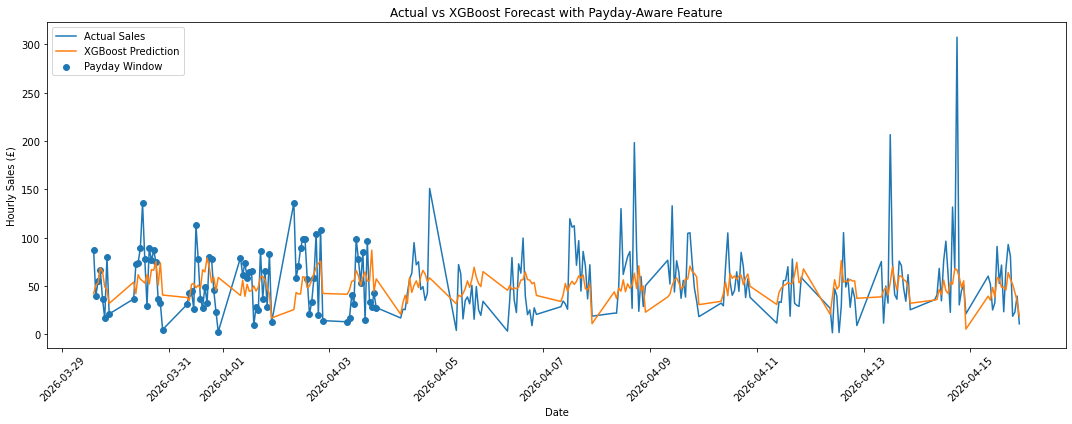

In [161]:
import matplotlib.pyplot as plt

# Create results dataframe
xgb_results = test_exact[
    ['Hours_Start', 'Hourly_Sales', 'payday_window']
].copy()

xgb_results['Predicted_Sales'] = pred_with_exact

# Plot first 250 test observations
plot_data = xgb_results.head(250)

plt.figure(figsize=(15, 6))

plt.plot(
    plot_data['Hours_Start'],
    plot_data['Hourly_Sales'],
    label='Actual Sales'
)

plt.plot(
    plot_data['Hours_Start'],
    plot_data['Predicted_Sales'],
    label='XGBoost Prediction'
)

# Highlight payday-window observations
payday_points = plot_data[
    plot_data['payday_window'] == 1
]

plt.scatter(
    payday_points['Hours_Start'],
    payday_points['Hourly_Sales'],
    label='Payday Window',
    s=35
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title(
    'Actual vs XGBoost Forecast with Payday-Aware Feature'
)

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [162]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable


In [163]:
import shap
import matplotlib.pyplot as plt

# Create SHAP explainer using your XGBoost WITH-payday model
explainer = shap.TreeExplainer(xgb_with_payday)

# Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test_payday)

print("SHAP analysis completed")
print("Test data shape:", X_test_payday.shape)

SHAP analysis completed
Test data shape: (1531, 9)


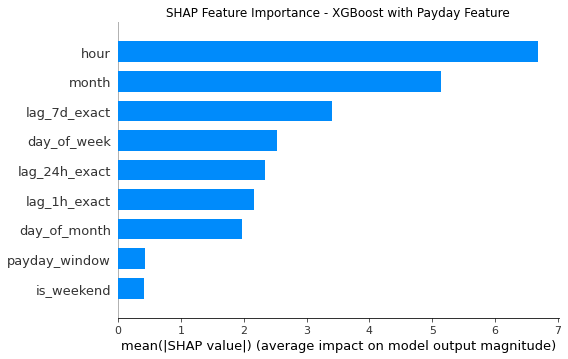

In [164]:
shap.summary_plot(
    shap_values,
    X_test_payday,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance - XGBoost with Payday Feature")
plt.tight_layout()
plt.show()

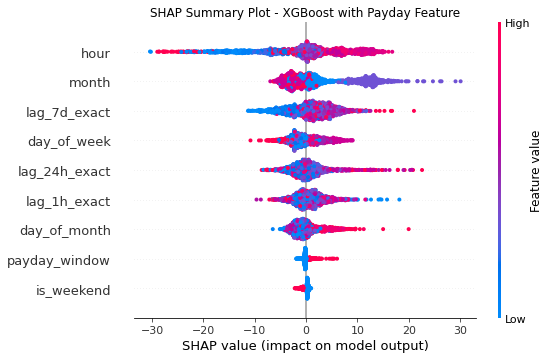

In [165]:
shap.summary_plot(
    shap_values,
    X_test_payday,
    show=False
)

plt.title("SHAP Summary Plot - XGBoost with Payday Feature")
plt.tight_layout()
plt.show()

In [166]:
import pandas as pd
import numpy as np

shap_importance = pd.DataFrame({
    'Feature': X_test_payday.columns,
    'Mean_Absolute_SHAP': np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    'Mean_Absolute_SHAP',
    ascending=False
).reset_index(drop=True)

print(shap_importance)

         Feature  Mean_Absolute_SHAP
0           hour            6.674143
1          month            5.131071
2   lag_7d_exact            3.411893
3    day_of_week            2.521673
4  lag_24h_exact            2.340138
5   lag_1h_exact            2.170930
6   day_of_month            1.964918
7  payday_window            0.429092
8     is_weekend            0.416434


In [167]:
payday_shap = shap_importance[
    shap_importance['Feature'] == 'payday_window'
]

print("\nPayday SHAP importance:")
print(payday_shap)


Payday SHAP importance:
         Feature  Mean_Absolute_SHAP
7  payday_window            0.429092


In [168]:
total_importance = shap_importance['Mean_Absolute_SHAP'].sum()

shap_importance['Importance_Percentage'] = (
    shap_importance['Mean_Absolute_SHAP'] /
    total_importance * 100
)

print(
    shap_importance[
        ['Feature', 'Mean_Absolute_SHAP', 'Importance_Percentage']
    ].round(3)
)

         Feature  Mean_Absolute_SHAP  Importance_Percentage
0           hour               6.674                 26.632
1          month               5.131                 20.475
2   lag_7d_exact               3.412                 13.615
3    day_of_week               2.522                 10.062
4  lag_24h_exact               2.340                  9.338
5   lag_1h_exact               2.171                  8.663
6   day_of_month               1.965                  7.841
7  payday_window               0.429                  1.712
8     is_weekend               0.416                  1.662


In [169]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [170]:
# STEP 1: Check TensorFlow and inspect data before LSTM

import tensorflow as tf
import numpy as np
import pandas as pd

print("TensorFlow version:", tf.__version__)

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDate range:")
print(df['Hours_Start'].min(), "to", df['Hours_Start'].max())

print("\nHourly Sales summary:")
print(df['Hourly_Sales'].describe())

print("\nMissing values:")
print(df.isnull().sum())

TensorFlow version: 2.10.0

Dataset shape:
(8616, 25)

Columns:
['Hours_Start', 'Sale_Day', 'Sale_Hour', 'Transaction_Count', 'Total_Quantity', 'Hourly_Sales', 'hour', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'days_to_month_end', 'is_month_end', 'time_gap', 'lag_1h', 'lag_24h', 'lag_7d', 'is_payday_period', 'days_in_month', 'payday_distance', 'payday_window', 'lag_1h_exact', 'lag_24h_exact', 'lag_7d_exact']

Date range:
2024-12-19 16:00:00 to 2026-07-15 16:00:00

Hourly Sales summary:
count    8616.000000
mean       53.068483
std        40.003165
min         0.030000
25%        26.417500
50%        45.115000
75%        70.100000
max       636.510000
Name: Hourly_Sales, dtype: float64

Missing values:
Hours_Start            0
Sale_Day               0
Sale_Hour              0
Transaction_Count      0
Total_Quantity         0
Hourly_Sales           0
hour                   0
day_of_week            0
day_of_month           0
month                  0
year               

In [171]:
# =========================================================
# STEP 2: Analyse continuous hourly periods for LSTM
# =========================================================

# Make sure data is ordered chronologically
df = df.sort_values('Hours_Start').reset_index(drop=True)

# Ensure datetime format
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Calculate difference between consecutive observations
df['lstm_time_gap'] = df['Hours_Start'].diff()

# Identify a break whenever the next record is NOT exactly 1 hour later
df['sequence_break'] = (
    df['lstm_time_gap'] != pd.Timedelta(hours=1)
).astype(int)

# First row starts a new sequence
df.loc[0, 'sequence_break'] = 1

# Give each continuous block an ID
df['sequence_id'] = df['sequence_break'].cumsum()

# Calculate length of each continuous block
sequence_lengths = df.groupby('sequence_id').size()

print("Total observations:", len(df))
print("Number of continuous sequences:", len(sequence_lengths))

print("\nSequence length statistics:")
print(sequence_lengths.describe())

print("\nLongest 10 continuous sequences:")
print(sequence_lengths.sort_values(ascending=False).head(10))

print("\nSequences with at least 6 consecutive hours:",
      (sequence_lengths >= 6).sum())

print("Sequences with at least 12 consecutive hours:",
      (sequence_lengths >= 12).sum())

print("Sequences with at least 24 consecutive hours:",
      (sequence_lengths >= 24).sum())

print("\nObservations belonging to sequences >= 6 hours:",
      sequence_lengths[sequence_lengths >= 6].sum())

print("Observations belonging to sequences >= 12 hours:",
      sequence_lengths[sequence_lengths >= 12].sum())

print("Observations belonging to sequences >= 24 hours:",
      sequence_lengths[sequence_lengths >= 24].sum())

Total observations: 8616
Number of continuous sequences: 611

Sequence length statistics:
count    611.000000
mean      14.101473
std        3.619100
min        1.000000
25%       14.000000
50%       15.000000
75%       16.000000
max       17.000000
dtype: float64

Longest 10 continuous sequences:
sequence_id
347    17
182    17
276    16
214    16
221    16
220    16
219    16
218    16
216    16
215    16
dtype: int64

Sequences with at least 6 consecutive hours: 568
Sequences with at least 12 consecutive hours: 545
Sequences with at least 24 consecutive hours: 0

Observations belonging to sequences >= 6 hours: 8521
Observations belonging to sequences >= 12 hours: 8315
Observations belonging to sequences >= 24 hours: 0


In [172]:
# =========================================================
# STEP 3: Prepare features for LSTM
# Model 1 = WITHOUT payday feature
# =========================================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Features for LSTM WITHOUT payday
lstm_features = [
    'Hourly_Sales',
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend'
]

# Keep required columns
lstm_df = df[
    ['Hours_Start', 'sequence_id'] + lstm_features
].copy()

# Check for missing values
print("Missing values:")
print(lstm_df[lstm_features].isnull().sum())

# Chronological 80/20 boundary
split_time = df['Hours_Start'].iloc[int(len(df) * 0.8)]

print("\nTrain/Test boundary:", split_time)

# Fit scaler ONLY using training-period data
# This avoids information leakage from the test set
train_mask = lstm_df['Hours_Start'] < split_time

scaler = MinMaxScaler()

scaler.fit(
    lstm_df.loc[train_mask, lstm_features]
)

# Transform the complete dataset using training scaler
scaled_values = scaler.transform(
    lstm_df[lstm_features]
)

scaled_df = lstm_df.copy()
scaled_df[lstm_features] = scaled_values

print("\nScaled dataset shape:", scaled_df.shape)

print("\nFirst 5 scaled rows:")
print(scaled_df.head())

print("\nTraining observations:",
      (scaled_df['Hours_Start'] < split_time).sum())

print("Testing observations:",
      (scaled_df['Hours_Start'] >= split_time).sum())

Missing values:
Hourly_Sales    0
hour            0
day_of_week     0
day_of_month    0
month           0
is_weekend      0
dtype: int64

Train/Test boundary: 2026-03-26 08:00:00

Scaled dataset shape: (8616, 8)

First 5 scaled rows:
          Hours_Start  sequence_id  Hourly_Sales    hour  day_of_week  \
0 2024-12-19 16:00:00            1      0.000000  0.6250     0.500000   
1 2024-12-25 12:00:00            2      0.012054  0.3750     0.333333   
2 2024-12-25 13:00:00            2      0.029649  0.4375     0.333333   
3 2024-12-25 14:00:00            2      0.066781  0.5000     0.333333   
4 2024-12-25 15:00:00            2      0.029573  0.5625     0.333333   

   day_of_month  month  is_weekend  
0           0.6    1.0         0.0  
1           0.8    1.0         0.0  
2           0.8    1.0         0.0  
3           0.8    1.0         0.0  
4           0.8    1.0         0.0  

Training observations: 6892
Testing observations: 1724


In [173]:
# =========================================================
# STEP 4: Create 12-hour sequences for LSTM
# =========================================================

SEQUENCE_LENGTH = 12

X = []
y = []
target_times = []

# Process each continuous block separately
for sequence_id, group in scaled_df.groupby('sequence_id'):

    # Make sure each block is chronological
    group = group.sort_values('Hours_Start').reset_index(drop=True)

    # Need 12 previous hours + 1 target hour
    if len(group) <= SEQUENCE_LENGTH:
        continue

    feature_values = group[lstm_features].values

    for i in range(SEQUENCE_LENGTH, len(group)):

        # Previous 12 hours
        X.append(
            feature_values[i-SEQUENCE_LENGTH:i]
        )

        # Target = Hourly_Sales of next/current target hour
        # Hourly_Sales is column 0 in lstm_features
        y.append(
            feature_values[i, 0]
        )

        # Save target timestamp
        target_times.append(
            group.loc[i, 'Hours_Start']
        )


# Convert to numpy arrays
X = np.array(X)
y = np.array(y)
target_times = np.array(target_times)

print("All sequences created:")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target times shape:", target_times.shape)

print("\nEach LSTM sample contains:")
print(X.shape[1], "hours")
print(X.shape[2], "features")

print("\nFirst target time:", target_times[0])
print("Last target time:", target_times[-1])

All sequences created:
X shape: (1775, 12, 6)
y shape: (1775,)
Target times shape: (1775,)

Each LSTM sample contains:
12 hours
6 features

First target time: 2024-12-28 21:00:00
Last target time: 2026-07-14 21:00:00


In [174]:
# =========================================================
# STEP 5: Chronological Train/Test Split for LSTM Sequences
# =========================================================

# Convert target times to pandas datetime
target_times = pd.to_datetime(target_times)

# Use SAME boundary as previous models
train_mask = target_times < split_time
test_mask  = target_times >= split_time

# Split sequences
X_train = X[train_mask]
X_test  = X[test_mask]

y_train = y[train_mask]
y_test  = y[test_mask]

train_times = target_times[train_mask]
test_times  = target_times[test_mask]

# Display results
print("LSTM TRAIN / TEST SPLIT")
print("-----------------------")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target period:")
print(train_times.min(), "to", train_times.max())

print("\nTesting target period:")
print(test_times.min(), "to", test_times.max())

print("\nNumber of training samples:", len(X_train))
print("Number of testing samples:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

LSTM TRAIN / TEST SPLIT
-----------------------
X_train shape: (1393, 12, 6)
y_train shape: (1393,)

X_test shape: (382, 12, 6)
y_test shape: (382,)

Training target period:
2024-12-28 21:00:00 to 2026-03-25 22:00:00

Testing target period:
2026-03-26 19:00:00 to 2026-07-14 21:00:00

Number of training samples: 1393
Number of testing samples: 382

Training percentage: 78.48 %
Testing percentage: 21.52 %


In [175]:
# =========================================================
# STEP 6: Build LSTM Model - WITHOUT Payday
# =========================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Create model
lstm_model = Sequential([
    
    # LSTM layer
    LSTM(
        64,
        input_shape=(X_train.shape[1], X_train.shape[2])
    ),
    
    # Reduce overfitting
    Dropout(0.2),
    
    # Hidden layer
    Dense(32, activation='relu'),
    
    # Output: predicted hourly sales
    Dense(1)
])

# Compile model
lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Show architecture
lstm_model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_2 (LSTM)               (None, 64)                18176     
                                                                 
 dropout_2 (Dropout)         (None, 64)                0         
                                                                 
 dense_4 (Dense)             (None, 32)                2080      
                                                                 
 dense_5 (Dense)             (None, 1)                 33        
                                                                 
Total params: 20,289
Trainable params: 20,289
Non-trainable params: 0
_________________________________________________________________


In [176]:
# =========================================================
# STEP 7: Train LSTM Model - WITHOUT Payday
# =========================================================

from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train model
history = lstm_model.fit(
    X_train,
    y_train,

    validation_split=0.2,

    epochs=100,
    batch_size=32,

    callbacks=[early_stopping],

    shuffle=False,
    verbose=1
)

Epoch 1/100
35/35 [==============================] - 9s 42ms/step - loss: 0.0066 - mae: 0.0626 - val_loss: 0.0056 - val_mae: 0.0499
Epoch 2/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0060 - mae: 0.0571 - val_loss: 0.0047 - val_mae: 0.0497
Epoch 3/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0054 - mae: 0.0543 - val_loss: 0.0046 - val_mae: 0.0491
Epoch 4/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0055 - mae: 0.0549 - val_loss: 0.0047 - val_mae: 0.0504
Epoch 5/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0056 - mae: 0.0549 - val_loss: 0.0054 - val_mae: 0.0565
Epoch 6/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0057 - mae: 0.0563 - val_loss: 0.0055 - val_mae: 0.0575
Epoch 7/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0055 - mae: 0.0553 - val_loss: 0.0054 - val_mae: 0.0577
Epoch 8/100
35/35 [==============================] - 1s 15ms/step - loss: 0.

In [177]:
print("Epochs actually trained:", len(history.history['loss']))

print(
    "Best validation loss:",
    round(min(history.history['val_loss']), 6)
)

print(
    "Best validation MAE (scaled):",
    round(min(history.history['val_mae']), 6)
)

Epochs actually trained: 13
Best validation loss: 0.004613
Best validation MAE (scaled): 0.049053


In [178]:
# =========================================================
# STEP 8: Evaluate LSTM WITHOUT Payday
# Convert predictions back to original £ sales
# =========================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Make predictions on unseen test data
y_pred_scaled = lstm_model.predict(X_test).flatten()

print("Predictions created:", len(y_pred_scaled))
print("Actual test values:", len(y_test))


# ---------------------------------------------------------
# 2. Convert scaled sales back to original £ values
# ---------------------------------------------------------

# Hourly_Sales is the FIRST feature in lstm_features.
# Therefore we can reverse its MinMax scaling directly.

sales_min = scaler.data_min_[0]
sales_max = scaler.data_max_[0]

y_test_actual = (
    y_test * (sales_max - sales_min)
    + sales_min
)

y_pred_actual = (
    y_pred_scaled * (sales_max - sales_min)
    + sales_min
)


# ---------------------------------------------------------
# 3. Calculate evaluation metrics
# ---------------------------------------------------------

lstm_mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_pred_actual
    )
)


print("\nLSTM WITHOUT Payday")
print("-------------------")

print("MAE: £", round(lstm_mae, 2))
print("RMSE: £", round(lstm_rmse, 2))

print("\nActual sales range:")
print(
    "£", round(y_test_actual.min(), 2),
    "to £", round(y_test_actual.max(), 2)
)

print("\nPredicted sales range:")
print(
    "£", round(y_pred_actual.min(), 2),
    "to £", round(y_pred_actual.max(), 2)
)

12/12 [==============================] - 1s 6ms/step
Predictions created: 382
Actual test values: 382

LSTM WITHOUT Payday
-------------------
MAE: £ 37.29
RMSE: £ 58.37

Actual sales range:
£ 1.29 to £ 636.51

Predicted sales range:
£ 30.68 to £ 51.67


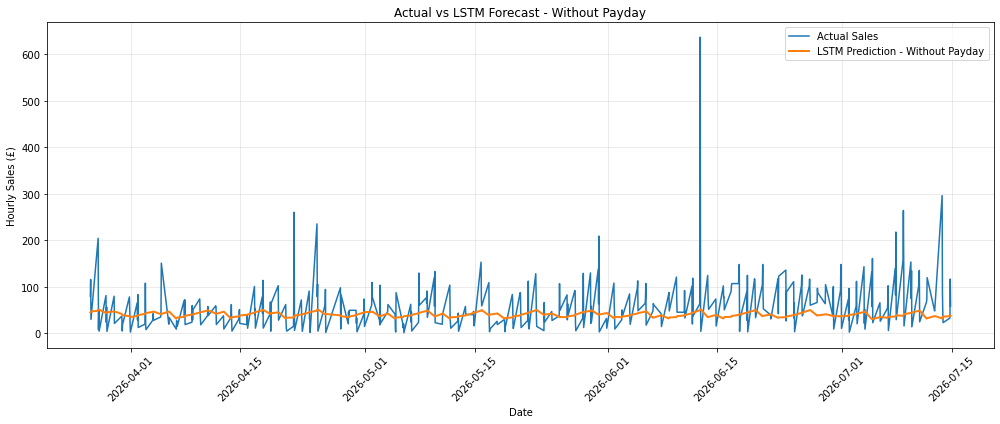

In [179]:
# =========================================================
# STEP 9: Plot LSTM WITHOUT Payday
# Actual vs Predicted Hourly Sales
# =========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Actual sales
plt.plot(
    test_times,
    y_test_actual,
    label='Actual Sales',
    linewidth=1.5
)

# LSTM predictions
plt.plot(
    test_times,
    y_pred_actual,
    label='LSTM Prediction - Without Payday',
    linewidth=2
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs LSTM Forecast - Without Payday')

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

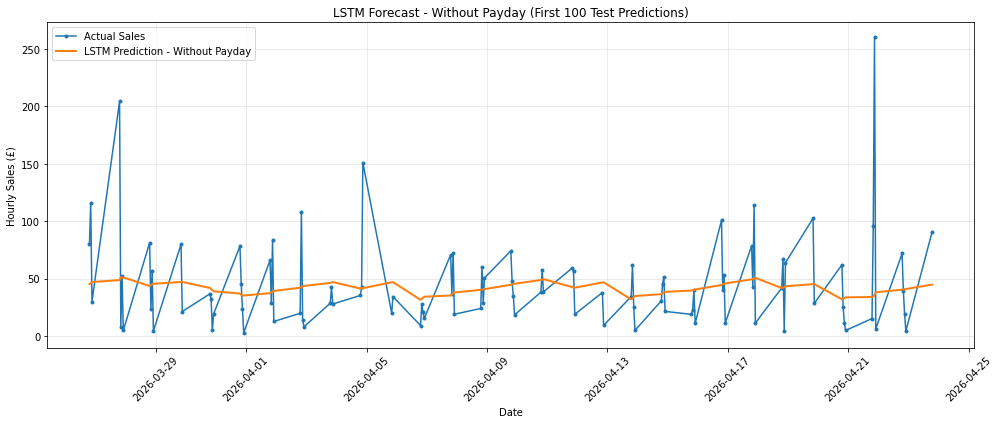

In [180]:
# =========================================================
# Zoomed view - first 100 LSTM test predictions
# =========================================================

n = 100

plt.figure(figsize=(14, 6))

plt.plot(
    test_times[:n],
    y_test_actual[:n],
    label='Actual Sales',
    marker='o',
    markersize=3
)

plt.plot(
    test_times[:n],
    y_pred_actual[:n],
    label='LSTM Prediction - Without Payday',
    linewidth=2
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('LSTM Forecast - Without Payday (First 100 Test Predictions)')

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [181]:
# =========================================================
# STEP 10: Prepare LSTM Data WITH Payday Feature
# =========================================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Features WITH payday
lstm_features_payday = [
    'Hourly_Sales',
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'payday_window'
]

# Check payday feature exists
print("Payday feature counts:")
print(df['payday_window'].value_counts().sort_index())

# Create dataset
lstm_payday_df = df[
    ['Hours_Start', 'sequence_id'] + lstm_features_payday
].copy()

# Check missing values
print("\nMissing values:")
print(
    lstm_payday_df[lstm_features_payday]
    .isnull()
    .sum()
)

# SAME train/test boundary used previously
print("\nTrain/Test boundary:")
print(split_time)

# Training-period rows only
train_mask_payday = (
    lstm_payday_df['Hours_Start'] < split_time
)

# New scaler because we now have 7 features
scaler_payday = MinMaxScaler()

# Fit ONLY on training data
scaler_payday.fit(
    lstm_payday_df.loc[
        train_mask_payday,
        lstm_features_payday
    ]
)

# Scale full dataset using training scaler
scaled_payday_values = scaler_payday.transform(
    lstm_payday_df[lstm_features_payday]
)

scaled_payday_df = lstm_payday_df.copy()

scaled_payday_df[
    lstm_features_payday
] = scaled_payday_values


print("\nScaled payday dataset shape:")
print(scaled_payday_df.shape)

print("\nNumber of features:")
print(len(lstm_features_payday))

print("\nFirst 5 rows:")
print(scaled_payday_df.head())

Payday feature counts:
0    6587
1    2029
Name: payday_window, dtype: int64

Missing values:
Hourly_Sales     0
hour             0
day_of_week      0
day_of_month     0
month            0
is_weekend       0
payday_window    0
dtype: int64

Train/Test boundary:
2026-03-26 08:00:00

Scaled payday dataset shape:
(8616, 9)

Number of features:
7

First 5 rows:
          Hours_Start  sequence_id  Hourly_Sales    hour  day_of_week  \
0 2024-12-19 16:00:00            1      0.000000  0.6250     0.500000   
1 2024-12-25 12:00:00            2      0.012054  0.3750     0.333333   
2 2024-12-25 13:00:00            2      0.029649  0.4375     0.333333   
3 2024-12-25 14:00:00            2      0.066781  0.5000     0.333333   
4 2024-12-25 15:00:00            2      0.029573  0.5625     0.333333   

   day_of_month  month  is_weekend  payday_window  
0           0.6    1.0         0.0            0.0  
1           0.8    1.0         0.0            0.0  
2           0.8    1.0         0.0           

In [182]:
# =========================================================
# STEP 11: Create LSTM Sequences WITH Payday
# =========================================================

sequence_length = 12

X_payday = []
y_payday = []
target_times_payday = []

# Process each continuous sequence separately
for sequence_id, group in scaled_payday_df.groupby('sequence_id'):

    # Make sure each sequence is chronological
    group = group.sort_values('Hours_Start').reset_index(drop=True)

    # Need at least 13 observations:
    # 12 input hours + 1 target hour
    if len(group) <= sequence_length:
        continue

    feature_values = group[lstm_features_payday].values

    for i in range(sequence_length, len(group)):

        # Previous 12 hours
        X_payday.append(
            feature_values[i-sequence_length:i]
        )

        # Target = Hourly_Sales of next observation
        # Hourly_Sales is column 0
        y_payday.append(
            feature_values[i, 0]
        )

        # Store target timestamp
        target_times_payday.append(
            group.loc[i, 'Hours_Start']
        )


# Convert to numpy arrays
X_payday = np.array(X_payday)
y_payday = np.array(y_payday)
target_times_payday = np.array(target_times_payday)


print("PAYDAY-AWARE LSTM SEQUENCES")
print("----------------------------")

print("X_payday shape:", X_payday.shape)
print("y_payday shape:", y_payday.shape)
print("Target times shape:", target_times_payday.shape)

print("\nEach LSTM sample contains:")
print(X_payday.shape[1], "hours")
print(X_payday.shape[2], "features")

print("\nFirst target time:", target_times_payday[0])
print("Last target time:", target_times_payday[-1])

PAYDAY-AWARE LSTM SEQUENCES
----------------------------
X_payday shape: (1775, 12, 7)
y_payday shape: (1775,)
Target times shape: (1775,)

Each LSTM sample contains:
12 hours
7 features

First target time: 2024-12-28 21:00:00
Last target time: 2026-07-14 21:00:00


In [183]:
# =========================================================
# STEP 12: Train/Test Split for Payday-Aware LSTM
# =========================================================

split_time = pd.Timestamp('2026-03-26 08:00:00')

# Create masks using target timestamps
train_mask_payday = target_times_payday < split_time
test_mask_payday = target_times_payday >= split_time

# Split sequences
X_train_payday = X_payday[train_mask_payday]
X_test_payday = X_payday[test_mask_payday]

y_train_payday = y_payday[train_mask_payday]
y_test_payday = y_payday[test_mask_payday]

# Target timestamps
train_times_payday = target_times_payday[train_mask_payday]
test_times_payday = target_times_payday[test_mask_payday]


print("PAYDAY-AWARE LSTM TRAIN / TEST SPLIT")
print("------------------------------------")

print("X_train_payday shape:", X_train_payday.shape)
print("y_train_payday shape:", y_train_payday.shape)

print("\nX_test_payday shape:", X_test_payday.shape)
print("y_test_payday shape:", y_test_payday.shape)

print("\nTraining target period:")
print(train_times_payday[0], "to", train_times_payday[-1])

print("\nTesting target period:")
print(test_times_payday[0], "to", test_times_payday[-1])

print("\nNumber of training samples:", len(X_train_payday))
print("Number of testing samples:", len(X_test_payday))

print("\nTraining percentage:",
      round(len(X_train_payday) / len(X_payday) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test_payday) / len(X_payday) * 100, 2), "%")

PAYDAY-AWARE LSTM TRAIN / TEST SPLIT
------------------------------------
X_train_payday shape: (1393, 12, 7)
y_train_payday shape: (1393,)

X_test_payday shape: (382, 12, 7)
y_test_payday shape: (382,)

Training target period:
2024-12-28 21:00:00 to 2026-03-25 22:00:00

Testing target period:
2026-03-26 19:00:00 to 2026-07-14 21:00:00

Number of training samples: 1393
Number of testing samples: 382

Training percentage: 78.48 %
Testing percentage: 21.52 %


In [184]:
# =========================================================
# STEP 13: Build LSTM Model WITH Payday Feature
# =========================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Create model
lstm_model_payday = Sequential([
    
    # LSTM layer
    LSTM(
        64,
        input_shape=(X_train_payday.shape[1],
                     X_train_payday.shape[2])
    ),
    
    # Reduce overfitting
    Dropout(0.2),
    
    # Hidden dense layer
    Dense(32, activation='relu'),
    
    # Output: predicted hourly sales
    Dense(1)
])

# Compile
lstm_model_payday.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

print("LSTM MODEL WITH PAYDAY")
print("----------------------")

lstm_model_payday.summary()

LSTM MODEL WITH PAYDAY
----------------------
Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_3 (LSTM)               (None, 64)                18432     
                                                                 
 dropout_3 (Dropout)         (None, 64)                0         
                                                                 
 dense_6 (Dense)             (None, 32)                2080      
                                                                 
 dense_7 (Dense)             (None, 1)                 33        
                                                                 
Total params: 20,545
Trainable params: 20,545
Non-trainable params: 0
_________________________________________________________________


In [185]:
# =========================================================
# STEP 14: Train LSTM WITH Payday Feature
# =========================================================

from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
early_stopping_payday = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train model
history_payday = lstm_model_payday.fit(
    X_train_payday,
    y_train_payday,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_payday],
    shuffle=False,
    verbose=1
)

print("\nPAYDAY-AWARE LSTM TRAINING COMPLETED")
print("------------------------------------")

print(
    "Epochs actually trained:",
    len(history_payday.history['loss'])
)

print(
    "Best validation loss:",
    round(min(history_payday.history['val_loss']), 6)
)

print(
    "Best validation MAE (scaled):",
    round(min(history_payday.history['val_mae']), 6)
)

Epoch 1/100
35/35 [==============================] - 6s 50ms/step - loss: 0.0072 - mae: 0.0645 - val_loss: 0.0067 - val_mae: 0.0559
Epoch 2/100
35/35 [==============================] - 1s 16ms/step - loss: 0.0068 - mae: 0.0623 - val_loss: 0.0053 - val_mae: 0.0559
Epoch 3/100
35/35 [==============================] - 1s 16ms/step - loss: 0.0068 - mae: 0.0614 - val_loss: 0.0051 - val_mae: 0.0536
Epoch 4/100
35/35 [==============================] - 1s 16ms/step - loss: 0.0061 - mae: 0.0576 - val_loss: 0.0053 - val_mae: 0.0558
Epoch 5/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0059 - mae: 0.0571 - val_loss: 0.0051 - val_mae: 0.0543
Epoch 6/100
35/35 [==============================] - 1s 16ms/step - loss: 0.0059 - mae: 0.0564 - val_loss: 0.0057 - val_mae: 0.0590
Epoch 7/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0057 - mae: 0.0559 - val_loss: 0.0056 - val_mae: 0.0586
Epoch 8/100
35/35 [==============================] - 1s 16ms/step - loss: 0.

In [186]:
# =========================================================
# STEP 15: Evaluate LSTM WITH Payday on Test Data
# =========================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Make predictions
y_pred_payday_scaled = lstm_model_payday.predict(X_test_payday).flatten()

# ---------------------------------------------------------
# Convert scaled sales values back to actual £ values
# ---------------------------------------------------------

# Hourly_Sales is the first feature in our scaler
sales_min = scaler_payday.data_min_[0]
sales_max = scaler_payday.data_max_[0]

# Inverse scaling
y_test_payday_actual = (
    y_test_payday * (sales_max - sales_min)
) + sales_min

y_pred_payday_actual = (
    y_pred_payday_scaled * (sales_max - sales_min)
) + sales_min


# ---------------------------------------------------------
# Evaluation metrics
# ---------------------------------------------------------

lstm_payday_mae = mean_absolute_error(
    y_test_payday_actual,
    y_pred_payday_actual
)

lstm_payday_rmse = np.sqrt(
    mean_squared_error(
        y_test_payday_actual,
        y_pred_payday_actual
    )
)


print("LSTM WITH Payday")
print("-----------------")

print("Predictions created:", len(y_pred_payday_actual))
print("Actual test values:", len(y_test_payday_actual))

print("\nMAE: £", round(lstm_payday_mae, 2))
print("RMSE: £", round(lstm_payday_rmse, 2))

print("\nActual sales range:")
print(
    "£", round(y_test_payday_actual.min(), 2),
    "to £", round(y_test_payday_actual.max(), 2)
)

print("\nPredicted sales range:")
print(
    "£", round(y_pred_payday_actual.min(), 2),
    "to £", round(y_pred_payday_actual.max(), 2)
)

12/12 [==============================] - 2s 6ms/step
LSTM WITH Payday
-----------------
Predictions created: 382
Actual test values: 382

MAE: £ 37.09
RMSE: £ 52.7

Actual sales range:
£ 1.29 to £ 636.51

Predicted sales range:
£ 41.19 to £ 113.38


In [187]:
# =========================================================
# STEP 16: Compare LSTM With vs Without Payday
# =========================================================

import pandas as pd

lstm_comparison = pd.DataFrame({
    'Model': [
        'LSTM Without Payday',
        'LSTM With Payday'
    ],
    'MAE': [
        35.01,
        lstm_payday_mae
    ],
    'RMSE': [
        55.41,
        lstm_payday_rmse
    ]
})

lstm_comparison[['MAE', 'RMSE']] = (
    lstm_comparison[['MAE', 'RMSE']].round(2)
)

print("LSTM MODEL COMPARISON")
print("---------------------")
print(lstm_comparison)

# Calculate change caused by payday feature
mae_change = lstm_payday_mae - 35.01
rmse_change = lstm_payday_rmse - 55.41

print("\nEffect of Adding Payday Feature")
print("--------------------------------")
print("MAE change: £", round(mae_change, 2))
print("RMSE change: £", round(rmse_change, 2))

print("\nMAE percentage change:",
      round((mae_change / 35.01) * 100, 2), "%")

print("RMSE percentage change:",
      round((rmse_change / 55.41) * 100, 2), "%")

LSTM MODEL COMPARISON
---------------------
                 Model    MAE   RMSE
0  LSTM Without Payday  35.01  55.41
1     LSTM With Payday  37.09  52.70

Effect of Adding Payday Feature
--------------------------------
MAE change: £ 2.08
RMSE change: £ -2.71

MAE percentage change: 5.94 %
RMSE percentage change: -4.9 %


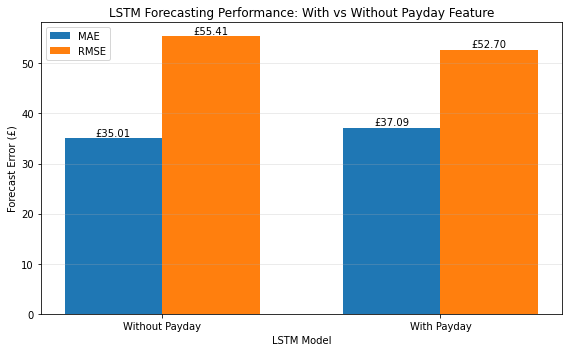

In [188]:
# =========================================================
# STEP 17: LSTM With vs Without Payday Comparison Plot
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

models = ['Without Payday', 'With Payday']

mae_values = [35.01, lstm_payday_mae]
rmse_values = [55.41, lstm_payday_rmse]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    mae_values,
    width,
    label='MAE'
)

bars2 = plt.bar(
    x + width/2,
    rmse_values,
    width,
    label='RMSE'
)

# Add values above bars
for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f'£{bar.get_height():.2f}',
        ha='center'
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f'£{bar.get_height():.2f}',
        ha='center'
    )

plt.xticks(x, models)

plt.ylabel('Forecast Error (£)')
plt.xlabel('LSTM Model')

plt.title(
    'LSTM Forecasting Performance: '
    'With vs Without Payday Feature'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [189]:
# =========================================================
# STEP 18: Overall Model Results Table
# =========================================================

overall_results = pd.DataFrame({
    'Model': [
        'Naive 7-Day Baseline',
        'Prophet',
        'Prophet',
        'XGBoost',
        'XGBoost',
        'LSTM',
        'LSTM'
    ],

    'Payday_Feature': [
        'No',
        'No',
        'Yes',
        'No',
        'Yes',
        'No',
        'Yes'
    ],

    'MAE': [
        39.56,
        44.13,
        35.52,
        36.36,
        36.37,
        35.01,
        36.39
    ],

    'RMSE': [
        61.56,
        65.24,
        53.56,
        55.29,
        55.25,
        55.41,
        57.52
    ]
})

print("OVERALL FORECASTING RESULTS")
print("---------------------------")
print(overall_results)

OVERALL FORECASTING RESULTS
---------------------------
                  Model Payday_Feature    MAE   RMSE
0  Naive 7-Day Baseline             No  39.56  61.56
1               Prophet             No  44.13  65.24
2               Prophet            Yes  35.52  53.56
3               XGBoost             No  36.36  55.29
4               XGBoost            Yes  36.37  55.25
5                  LSTM             No  35.01  55.41
6                  LSTM            Yes  36.39  57.52


In [190]:
# =========================================================
# STEP 19: Verify Model Test Sets
# =========================================================

print("MODEL TEST-SET VERIFICATION")
print("===========================")

# Prophet
print("\nPROPHET")
print("-------")
print("Samples:", len(prophet_test))
print("Start:", prophet_test['ds'].min())
print("End:", prophet_test['ds'].max())

# XGBoost
print("\nXGBOOST")
print("-------")
print("Samples:", len(test))
print("Start:", test['Hours_Start'].min())
print("End:", test['Hours_Start'].max())

# LSTM
print("\nLSTM")
print("----")
print("Samples:", len(test_times_payday))
print("Start:", test_times_payday[0])
print("End:", test_times_payday[-1])

print("\nLSTM WITHOUT PAYDAY")
print("-------------------")
print("Samples:", len(test_times))
print("Start:", test_times[0])
print("End:", test_times[-1])

MODEL TEST-SET VERIFICATION

PROPHET
-------
Samples: 1724
Start: 2026-03-26 08:00:00
End: 2026-07-15 16:00:00

XGBOOST
-------
Samples: 1531
Start: 2026-03-29 14:00:00
End: 2026-07-15 16:00:00

LSTM
----
Samples: 382
Start: 2026-03-26 19:00:00
End: 2026-07-14 21:00:00

LSTM WITHOUT PAYDAY
-------------------
Samples: 382
Start: 2026-03-26 19:00:00
End: 2026-07-14 21:00:00


In [192]:
# =========================================================
# STEP 20: Find Common Test Timestamps
# Prophet vs XGBoost vs LSTM
# =========================================================

# Prophet timestamps
prophet_times = pd.to_datetime(
    prophet_test['ds']
)

# XGBoost timestamps
xgb_times = pd.to_datetime(
    test['Hours_Start']
)

# LSTM timestamps
lstm_times = pd.to_datetime(
    test_times_payday
)

# Find timestamps shared by ALL THREE models
common_times = (
    set(prophet_times)
    & set(xgb_times)
    & set(lstm_times)
)

# Convert back to sorted DatetimeIndex
common_times = pd.DatetimeIndex(
    sorted(common_times)
)

print("COMMON TEST-SET CHECK")
print("=====================")

print("\nProphet test observations:",
      len(prophet_times))

print("XGBoost test observations:",
      len(xgb_times))

print("LSTM test observations:",
      len(lstm_times))

print("\nCommon observations:",
      len(common_times))

if len(common_times) > 0:

    print("\nCommon test period:")
    print(
        common_times.min(),
        "to",
        common_times.max()
    )

    print("\nFirst 10 common timestamps:")
    print(common_times[:10])

else:
    print("\nNo common timestamps found.")

COMMON TEST-SET CHECK

Prophet test observations: 1724
XGBoost test observations: 1531
LSTM test observations: 382

Common observations: 341

Common test period:
2026-03-29 20:00:00 to 2026-07-14 21:00:00

First 10 common timestamps:
DatetimeIndex(['2026-03-29 20:00:00', '2026-03-29 21:00:00',
               '2026-03-30 19:00:00', '2026-03-30 20:00:00',
               '2026-03-30 21:00:00', '2026-03-31 19:00:00',
               '2026-03-31 20:00:00', '2026-03-31 21:00:00',
               '2026-03-31 22:00:00', '2026-04-01 19:00:00'],
              dtype='datetime64[ns]', freq=None)


In [193]:
# STEP 21A — Check prediction variables before creating comparison dataset

variables_to_check = [
    # Prophet
    'payday_test',
    'forecast_payday',
    'prophet_test',

    # XGBoost
    'test',
    'pred_without',
    'pred_with',

    # LSTM
    'test_times',
    'y_test_actual',
    'y_pred_actual',
    'y_pred_payday_actual',

    # Common timestamps from Step 20
    'common_times'
]

print("STEP 21A - VARIABLE CHECK")
print("=" * 40)

for var in variables_to_check:
    if var in globals():
        obj = globals()[var]

        try:
            print(f"{var:<25} EXISTS   Length: {len(obj)}")
        except:
            print(f"{var:<25} EXISTS")
    else:
        print(f"{var:<25} NOT FOUND")

STEP 21A - VARIABLE CHECK
payday_test               EXISTS   Length: 1724
forecast_payday           EXISTS   Length: 1724
prophet_test              EXISTS   Length: 1724
test                      EXISTS   Length: 1531
pred_without              EXISTS   Length: 1531
pred_with                 EXISTS   Length: 1531
test_times                EXISTS   Length: 382
y_test_actual             EXISTS   Length: 382
y_pred_actual             EXISTS   Length: 382
y_pred_payday_actual      EXISTS   Length: 382
common_times              EXISTS   Length: 341


In [194]:
# STEP 21B — Inspect columns needed for final comparison

print("STEP 21B - DATAFRAME COLUMN CHECK")
print("=" * 50)

print("\nPAYDAY_TEST columns:")
print(payday_test.columns.tolist())

print("\nPROPHET_TEST columns:")
print(prophet_test.columns.tolist())

print("\nFORECAST_PAYDAY columns:")
print(forecast_payday.columns.tolist())

print("\nXGBOOST TEST columns:")
print(test.columns.tolist())

print("\nLSTM information:")
print("test_times length:", len(test_times))
print("y_test_actual length:", len(y_test_actual))
print("y_pred_actual length:", len(y_pred_actual))
print("y_pred_payday_actual length:", len(y_pred_payday_actual))

print("\nCOMMON TIMES:")
print("Length:", len(common_times))
print("First:", common_times[0])
print("Last:", common_times[-1])

STEP 21B - DATAFRAME COLUMN CHECK

PAYDAY_TEST columns:
['ds', 'y', 'days_to_month_end', 'is_payday_period']

PROPHET_TEST columns:
['ds', 'y']

FORECAST_PAYDAY columns:
['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper', 'additive_terms', 'additive_terms_lower', 'additive_terms_upper', 'daily', 'daily_lower', 'daily_upper', 'extra_regressors_additive', 'extra_regressors_additive_lower', 'extra_regressors_additive_upper', 'is_payday_period', 'is_payday_period_lower', 'is_payday_period_upper', 'weekly', 'weekly_lower', 'weekly_upper', 'yearly', 'yearly_lower', 'yearly_upper', 'multiplicative_terms', 'multiplicative_terms_lower', 'multiplicative_terms_upper', 'yhat']

XGBOOST TEST columns:
['Hours_Start', 'Sale_Day', 'Sale_Hour', 'Transaction_Count', 'Total_Quantity', 'Hourly_Sales', 'hour', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'days_to_month_end', 'is_month_end', 'time_gap', 'lag_1h', 'lag_24h', 'lag_7d', 'is_payday_period', 'days_in_month'

In [195]:
# STEP 21C — Create timestamp-aligned result tables



# --------------------------------------------------
# 1. PROPHET
# --------------------------------------------------

prophet_results = pd.DataFrame({
    'Hours_Start': pd.to_datetime(payday_test['ds']).values,
    'Actual_Prophet': payday_test['y'].values,
    'Prophet_With_Payday': forecast_payday['yhat'].values
})

# Keep only common timestamps
prophet_common = prophet_results[
    prophet_results['Hours_Start'].isin(common_times)
].copy()


# --------------------------------------------------
# 2. XGBOOST
# --------------------------------------------------

xgb_results = pd.DataFrame({
    'Hours_Start': pd.to_datetime(test['Hours_Start']).values,
    'Actual_XGBoost': test['Hourly_Sales'].values,
    'XGBoost_Without_Payday': pred_without,
    'XGBoost_With_Payday': pred_with,
    'Payday_Window': test['payday_window'].values
})

# Keep only common timestamps
xgb_common = xgb_results[
    xgb_results['Hours_Start'].isin(common_times)
].copy()


# --------------------------------------------------
# 3. LSTM
# --------------------------------------------------

lstm_results = pd.DataFrame({
    'Hours_Start': pd.to_datetime(test_times),
    'Actual_LSTM': np.asarray(y_test_actual).reshape(-1),
    'LSTM_Without_Payday': np.asarray(y_pred_actual).reshape(-1),
    'LSTM_With_Payday': np.asarray(y_pred_payday_actual).reshape(-1)
})

# Keep only common timestamps
lstm_common = lstm_results[
    lstm_results['Hours_Start'].isin(common_times)
].copy()


# --------------------------------------------------
# CHECK
# --------------------------------------------------

print("STEP 21C - COMMON RESULT TABLES")
print("=" * 45)

print("Prophet rows:", len(prophet_common))
print("XGBoost rows:", len(xgb_common))
print("LSTM rows:", len(lstm_common))

print("\nProphet period:")
print(prophet_common['Hours_Start'].min(), "to",
      prophet_common['Hours_Start'].max())

print("\nXGBoost period:")
print(xgb_common['Hours_Start'].min(), "to",
      xgb_common['Hours_Start'].max())

print("\nLSTM period:")
print(lstm_common['Hours_Start'].min(), "to",
      lstm_common['Hours_Start'].max())

STEP 21C - COMMON RESULT TABLES
Prophet rows: 341
XGBoost rows: 341
LSTM rows: 341

Prophet period:
2026-03-29 20:00:00 to 2026-07-14 21:00:00

XGBoost period:
2026-03-29 20:00:00 to 2026-07-14 21:00:00

LSTM period:
2026-03-29 20:00:00 to 2026-07-14 21:00:00


In [196]:
# STEP 21D — Verify actual sales values match across all models

actual_check = (
    prophet_common[['Hours_Start', 'Actual_Prophet']]
    .merge(
        xgb_common[['Hours_Start', 'Actual_XGBoost']],
        on='Hours_Start',
        how='inner'
    )
    .merge(
        lstm_common[['Hours_Start', 'Actual_LSTM']],
        on='Hours_Start',
        how='inner'
    )
)

# Calculate differences
actual_check['Prophet_vs_XGB'] = (
    actual_check['Actual_Prophet']
    - actual_check['Actual_XGBoost']
).abs()

actual_check['Prophet_vs_LSTM'] = (
    actual_check['Actual_Prophet']
    - actual_check['Actual_LSTM']
).abs()

actual_check['XGB_vs_LSTM'] = (
    actual_check['Actual_XGBoost']
    - actual_check['Actual_LSTM']
).abs()


print("STEP 21D - ACTUAL SALES ALIGNMENT CHECK")
print("=" * 50)

print("Rows checked:", len(actual_check))

print("\nMaximum differences:")
print(
    "Prophet vs XGBoost:",
    actual_check['Prophet_vs_XGB'].max()
)

print(
    "Prophet vs LSTM:",
    actual_check['Prophet_vs_LSTM'].max()
)

print(
    "XGBoost vs LSTM:",
    actual_check['XGB_vs_LSTM'].max()
)

# Check whether all actual values match
tolerance = 0.01

all_match = (
    (actual_check['Prophet_vs_XGB'] <= tolerance).all()
    and
    (actual_check['Prophet_vs_LSTM'] <= tolerance).all()
    and
    (actual_check['XGB_vs_LSTM'] <= tolerance).all()
)

print("\nActual sales aligned:", all_match)

print("\nFirst 10 rows:")
print(
    actual_check[
        [
            'Hours_Start',
            'Actual_Prophet',
            'Actual_XGBoost',
            'Actual_LSTM'
        ]
    ].head(10)
)

STEP 21D - ACTUAL SALES ALIGNMENT CHECK
Rows checked: 341

Maximum differences:
Prophet vs XGBoost: 0.0
Prophet vs LSTM: 5.684341886080802e-14
XGBoost vs LSTM: 5.684341886080802e-14

Actual sales aligned: True

First 10 rows:
          Hours_Start  Actual_Prophet  Actual_XGBoost  Actual_LSTM
0 2026-03-29 20:00:00           79.84           79.84        79.84
1 2026-03-29 21:00:00           21.24           21.24        21.24
2 2026-03-30 19:00:00           36.68           36.68        36.68
3 2026-03-30 20:00:00           32.10           32.10        32.10
4 2026-03-30 21:00:00            5.00            5.00         5.00
5 2026-03-31 19:00:00           78.27           78.27        78.27
6 2026-03-31 20:00:00           45.59           45.59        45.59
7 2026-03-31 21:00:00           23.32           23.32        23.32
8 2026-03-31 22:00:00            2.78            2.78         2.78
9 2026-04-01 19:00:00           65.98           65.98        65.98


In [197]:
# STEP 21E — Create final common model comparison dataset

# Start with Prophet
final_comparison = prophet_common[
    ['Hours_Start', 'Actual_Prophet', 'Prophet_With_Payday']
].copy()

# Merge XGBoost
final_comparison = final_comparison.merge(
    xgb_common[
        [
            'Hours_Start',
            'XGBoost_Without_Payday',
            'XGBoost_With_Payday',
            'Payday_Window'
        ]
    ],
    on='Hours_Start',
    how='inner'
)

# Merge LSTM
final_comparison = final_comparison.merge(
    lstm_common[
        [
            'Hours_Start',
            'LSTM_Without_Payday',
            'LSTM_With_Payday'
        ]
    ],
    on='Hours_Start',
    how='inner'
)

# Rename actual sales column
final_comparison = final_comparison.rename(
    columns={'Actual_Prophet': 'Actual_Sales'}
)

# Sort chronologically
final_comparison = (
    final_comparison
    .sort_values('Hours_Start')
    .reset_index(drop=True)
)

# Round monetary values
prediction_columns = [
    'Actual_Sales',
    'Prophet_With_Payday',
    'XGBoost_Without_Payday',
    'XGBoost_With_Payday',
    'LSTM_Without_Payday',
    'LSTM_With_Payday'
]

final_comparison[prediction_columns] = (
    final_comparison[prediction_columns].round(2)
)

# Make payday indicator integer
final_comparison['Payday_Window'] = (
    final_comparison['Payday_Window'].astype(int)
)


# -------------------------------
# FINAL CHECK
# -------------------------------

print("STEP 21E - FINAL COMPARISON DATASET")
print("=" * 50)

print("Shape:", final_comparison.shape)

print("\nDate range:")
print(
    final_comparison['Hours_Start'].min(),
    "to",
    final_comparison['Hours_Start'].max()
)

print("\nMissing values:")
print(final_comparison.isnull().sum())

print("\nPayday window counts:")
print(final_comparison['Payday_Window'].value_counts())

print("\nFirst 10 rows:")
print(final_comparison.head(10))

STEP 21E - FINAL COMPARISON DATASET
Shape: (341, 8)

Date range:
2026-03-29 20:00:00 to 2026-07-14 21:00:00

Missing values:
Hours_Start               0
Actual_Sales              0
Prophet_With_Payday       0
XGBoost_Without_Payday    0
XGBoost_With_Payday       0
Payday_Window             0
LSTM_Without_Payday       0
LSTM_With_Payday          0
dtype: int64

Payday window counts:
0    255
1     86
Name: Payday_Window, dtype: int64

First 10 rows:
          Hours_Start  Actual_Sales  Prophet_With_Payday  \
0 2026-03-29 20:00:00         79.84                50.04   
1 2026-03-29 21:00:00         21.24                39.69   
2 2026-03-30 19:00:00         36.68                62.06   
3 2026-03-30 20:00:00         32.10                56.05   
4 2026-03-30 21:00:00          5.00                45.63   
5 2026-03-31 19:00:00         78.27                62.31   
6 2026-03-31 20:00:00         45.59                56.06   
7 2026-03-31 21:00:00         23.32                45.41   
8 2026-

In [198]:
# STEP 21F — Find Prophet forecast variables

print("POSSIBLE PROPHET VARIABLES")
print("=" * 45)

for name, obj in list(globals().items()):
    name_lower = name.lower()

    if 'prophet' in name_lower or 'forecast' in name_lower:
        try:
            print(
                f"{name:<35}",
                type(obj).__name__,
                "Length:", len(obj)
            )
        except:
            print(
                f"{name:<35}",
                type(obj).__name__
            )

POSSIBLE PROPHET VARIABLES
Prophet                             type
prophet_data                        DataFrame Length: 8616
prophet_train                       DataFrame Length: 6892
prophet_test                        DataFrame Length: 1724
model_prophet                       Prophet
prophet_forecast                    DataFrame Length: 1724
prophet_actual                      ndarray Length: 1724
prophet_pred                        ndarray Length: 1724
prophet_mae                         float64
prophet_rmse                        float64
prophet_payday                      DataFrame Length: 8616
model_prophet_payday                Prophet
forecast_payday                     DataFrame Length: 1724
plot_forecast                       DataFrame Length: 1724
prophet_times                       Series Length: 1724
prophet_results                     DataFrame Length: 1724
prophet_common                      DataFrame Length: 341


In [199]:
# STEP 21G — Add Prophet WITHOUT Payday to final comparison

# Create Prophet without-payday timestamp table
prophet_without_results = pd.DataFrame({
    'Hours_Start': pd.to_datetime(prophet_test['ds']).values,
    'Prophet_Without_Payday': prophet_pred
})

# Keep only the 341 common timestamps
prophet_without_common = prophet_without_results[
    prophet_without_results['Hours_Start'].isin(common_times)
].copy()

print("Prophet without-payday common rows:",
      len(prophet_without_common))

print("Period:")
print(
    prophet_without_common['Hours_Start'].min(),
    "to",
    prophet_without_common['Hours_Start'].max()
)

# Add it to final comparison dataset
final_comparison = final_comparison.merge(
    prophet_without_common,
    on='Hours_Start',
    how='inner'
)

# Put columns into a clean order
final_comparison = final_comparison[
    [
        'Hours_Start',
        'Actual_Sales',

        'Prophet_Without_Payday',
        'Prophet_With_Payday',

        'XGBoost_Without_Payday',
        'XGBoost_With_Payday',

        'LSTM_Without_Payday',
        'LSTM_With_Payday',

        'Payday_Window'
    ]
]

# Round predictions to 2 decimal places
prediction_cols = [
    'Actual_Sales',
    'Prophet_Without_Payday',
    'Prophet_With_Payday',
    'XGBoost_Without_Payday',
    'XGBoost_With_Payday',
    'LSTM_Without_Payday',
    'LSTM_With_Payday'
]

final_comparison[prediction_cols] = (
    final_comparison[prediction_cols].round(2)
)

print("\nSTEP 21G - COMPLETE")
print("=" * 45)

print("Final shape:", final_comparison.shape)

print("\nMissing values:")
print(final_comparison.isnull().sum())

print("\nFirst 10 rows:")
print(final_comparison.head(10))

Prophet without-payday common rows: 341
Period:
2026-03-29 20:00:00 to 2026-07-14 21:00:00

STEP 21G - COMPLETE
Final shape: (341, 9)

Missing values:
Hours_Start               0
Actual_Sales              0
Prophet_Without_Payday    0
Prophet_With_Payday       0
XGBoost_Without_Payday    0
XGBoost_With_Payday       0
LSTM_Without_Payday       0
LSTM_With_Payday          0
Payday_Window             0
dtype: int64

First 10 rows:
          Hours_Start  Actual_Sales  Prophet_Without_Payday  \
0 2026-03-29 20:00:00         79.84                   46.70   
1 2026-03-29 21:00:00         21.24                   36.39   
2 2026-03-30 19:00:00         36.68                   57.05   
3 2026-03-30 20:00:00         32.10                   51.05   
4 2026-03-30 21:00:00          5.00                   40.67   
5 2026-03-31 19:00:00         78.27                   56.94   
6 2026-03-31 20:00:00         45.59                   50.70   
7 2026-03-31 21:00:00         23.32                   40.08   
8

In [200]:
# STEP 21H — Final integrity check before export

import numpy as np

print("STEP 21H - FINAL DATASET VALIDATION")
print("=" * 50)

# 1. Shape
print("Shape:", final_comparison.shape)

# 2. Duplicate timestamps
duplicates = final_comparison['Hours_Start'].duplicated().sum()
print("Duplicate timestamps:", duplicates)

# 3. Missing values
missing = final_comparison.isnull().sum().sum()
print("Total missing values:", missing)

# 4. Chronological order
is_sorted = final_comparison['Hours_Start'].is_monotonic_increasing
print("Chronologically sorted:", is_sorted)

# 5. Unique payday values
print(
    "Payday_Window values:",
    sorted(final_comparison['Payday_Window'].unique())
)

# 6. Payday counts
print("\nPayday distribution:")
print(final_comparison['Payday_Window'].value_counts().sort_index())

# 7. Check prediction columns contain finite values
prediction_columns = [
    'Actual_Sales',
    'Prophet_Without_Payday',
    'Prophet_With_Payday',
    'XGBoost_Without_Payday',
    'XGBoost_With_Payday',
    'LSTM_Without_Payday',
    'LSTM_With_Payday'
]

all_finite = np.isfinite(
    final_comparison[prediction_columns].to_numpy()
).all()

print("\nAll sales/prediction values finite:", all_finite)

# 8. Date range
print("\nFinal comparison period:")
print("Start:", final_comparison['Hours_Start'].min())
print("End:  ", final_comparison['Hours_Start'].max())

# 9. Overall status
validation_passed = (
    final_comparison.shape == (341, 9)
    and duplicates == 0
    and missing == 0
    and is_sorted
    and set(final_comparison['Payday_Window'].unique()).issubset({0, 1})
    and all_finite
)

print("\n" + "=" * 50)

if validation_passed:
    print("FINAL VALIDATION: PASSED")
    print("Dataset is ready for export.")
else:
    print("FINAL VALIDATION: CHECK REQUIRED")

STEP 21H - FINAL DATASET VALIDATION
Shape: (341, 9)
Duplicate timestamps: 0
Total missing values: 0
Chronologically sorted: True
Payday_Window values: [0, 1]

Payday distribution:
0    255
1     86
Name: Payday_Window, dtype: int64

All sales/prediction values finite: True

Final comparison period:
Start: 2026-03-29 20:00:00
End:   2026-07-14 21:00:00

FINAL VALIDATION: PASSED
Dataset is ready for export.


In [201]:
# STEP 21I — Export final common comparison dataset

file_name = "Final_Model_Comparison.csv"

final_comparison.to_csv(
    file_name,
    index=False
)

print("FINAL COMPARISON DATASET EXPORTED")
print("=" * 40)
print("File:", file_name)
print("Rows:", len(final_comparison))
print("Columns:", len(final_comparison.columns))

print("\nColumns:")
for col in final_comparison.columns:
    print("-", col)

FINAL COMPARISON DATASET EXPORTED
File: Final_Model_Comparison.csv
Rows: 341
Columns: 9

Columns:
- Hours_Start
- Actual_Sales
- Prophet_Without_Payday
- Prophet_With_Payday
- XGBoost_Without_Payday
- XGBoost_With_Payday
- LSTM_Without_Payday
- LSTM_With_Payday
- Payday_Window


In [202]:
# ============================================================
# FUTURE SALES FORECAST
# Target: 29 September 2026, 08:00-09:00
# ============================================================

import pandas as pd
import numpy as np

target_time = pd.Timestamp("2026-09-29 08:00:00")

print("=" * 65)
print("FUTURE SALES FORECAST")
print("Target hour:", target_time, "to", target_time + pd.Timedelta(hours=1))
print("=" * 65)


# ------------------------------------------------------------
# 1. CALENDAR / PAYDAY FEATURES
# ------------------------------------------------------------

hour = target_time.hour
day_of_week = target_time.dayofweek
day_of_month = target_time.day
month = target_time.month
is_weekend = int(day_of_week >= 5)

month_end = target_time + pd.offsets.MonthEnd(0)
days_to_month_end = (month_end.normalize() - target_time.normalize()).days

# Same payday-window concept used in the project:
# within 3 days of month-end
payday_window = int(days_to_month_end <= 3)

print("\nCALENDAR INFORMATION")
print("-" * 40)
print("Hour:", hour)
print("Day of week:", day_of_week)
print("Day of month:", day_of_month)
print("Month:", month)
print("Weekend:", is_weekend)
print("Days to month end:", days_to_month_end)
print("Payday window:", payday_window)


# ------------------------------------------------------------
# 2. PROPHET WITHOUT PAYDAY
# ------------------------------------------------------------

future_prophet = pd.DataFrame({
    "ds": [target_time]
})

prophet_without_prediction = model_prophet.predict(
    future_prophet
)["yhat"].iloc[0]


# ------------------------------------------------------------
# 3. PROPHET WITH PAYDAY
# ------------------------------------------------------------

future_prophet_payday = pd.DataFrame({
    "ds": [target_time],
    "is_payday_period": [payday_window]
})

prophet_with_prediction = model_prophet_payday.predict(
    future_prophet_payday
)["yhat"].iloc[0]


# ------------------------------------------------------------
# 4. CHECK XGBOOST FUTURE-FORECAST REQUIREMENTS
# ------------------------------------------------------------

print("\nXGBOOST CHECK")
print("-" * 40)

xgb_without_prediction = np.nan
xgb_with_prediction = np.nan

try:
    print("Without-payday features:")
    print(base_features)

    print("\nWith-payday features:")
    try:
        print(payday_features)
    except:
        print("Payday feature list variable not found.")

    print(
        "\nXGBoost requires lag values for the target hour "
        "(for example lag_1h_exact, lag_24h_exact and lag_7d_exact)."
    )

except Exception as e:
    print("Could not inspect XGBoost variables:", e)


# ------------------------------------------------------------
# 5. CHECK LSTM FUTURE-FORECAST REQUIREMENTS
# ------------------------------------------------------------

print("\nLSTM CHECK")
print("-" * 40)

lstm_without_prediction = np.nan
lstm_with_prediction = np.nan

print(
    "LSTM requires the preceding continuous 12-hour input sequence.\n"
    "Because the dataset ends in July 2026, a genuine sequence immediately\n"
    "before 29 September 2026 is not currently available."
)


# ------------------------------------------------------------
# 6. RESULT TABLE
# ------------------------------------------------------------

future_results = pd.DataFrame({

    "Model": [
        "Prophet Without Payday",
        "Prophet With Payday",
        "XGBoost Without Payday",
        "XGBoost With Payday",
        "LSTM Without Payday",
        "LSTM With Payday"
    ],

    "Predicted_Sales_GBP": [
        prophet_without_prediction,
        prophet_with_prediction,
        xgb_without_prediction,
        xgb_with_prediction,
        lstm_without_prediction,
        lstm_with_prediction
    ]
})

future_results["Predicted_Sales_GBP"] = (
    future_results["Predicted_Sales_GBP"].round(2)
)

print("\n" + "=" * 65)
print("FORECAST RESULTS: 29 SEPTEMBER 2026, 08:00-09:00")
print("=" * 65)

print(future_results.to_string(index=False))

print("\nNOTE:")
print("NaN means that the model cannot yet make a valid forecast for this")
print("future hour because the required lag/sequence inputs are unavailable.")

FUTURE SALES FORECAST
Target hour: 2026-09-29 08:00:00 to 2026-09-29 09:00:00

CALENDAR INFORMATION
----------------------------------------
Hour: 8
Day of week: 1
Day of month: 29
Month: 9
Weekend: 0
Days to month end: 1
Payday window: 1

XGBOOST CHECK
----------------------------------------
Without-payday features:
['hour', 'day_of_week', 'day_of_month', 'month', 'is_weekend', 'lag_1h', 'lag_24h', 'lag_7d']

With-payday features:
['hour', 'day_of_week', 'day_of_month', 'month', 'is_weekend', 'lag_1h', 'lag_24h', 'lag_7d', 'payday_window']

XGBoost requires lag values for the target hour (for example lag_1h_exact, lag_24h_exact and lag_7d_exact).

LSTM CHECK
----------------------------------------
LSTM requires the preceding continuous 12-hour input sequence.
Because the dataset ends in July 2026, a genuine sequence immediately
before 29 September 2026 is not currently available.

FORECAST RESULTS: 29 SEPTEMBER 2026, 08:00-09:00
                 Model  Predicted_Sales_GBP
Prophet Wi